# ICT4403 Assignment 3 — English-to-French translation

Comparison of a randomly initialized encoder–decoder Transformer, fine-tuned mT5,
and zero-shot prompted LLaMA and Gemma.

## How to use this notebook

**Default: review the existing results.** Keep `RUN_EXPERIMENTS = False` and point
`PROJECT_DIR` at the folder containing the submitted `data/` and `results/` files.
No model training, downloads of model weights, or authentication are needed in
review mode. The notebook regenerates comparison figures from the saved files.

**Fresh reproduction:** set `RUN_EXPERIMENTS = True`, choose a **new, empty**
`EXPERIMENT_ROOT`, use a GPU runtime, and accept Hugging Face model access terms.
Training mT5 previously took about 67 minutes on a T4. This mode reconstructs the
data pipeline and all experiments; timings and sampled outputs may vary.
An interrupted run is not automatically resumed: preserve its checkpoints.

Run the setup cell first. If package installation changes imported versions,
restart the runtime before proceeding. This notebook targets the recorded
Transformers 4.51.3 environment, rather than arbitrary latest package releases.

**Evidence:** retained outputs below are historical outputs from the supplied
notebook, not a new execution of this edited notebook. Modified workflow code
has been statically checked, but the full GPU pipeline has not been rerun.
The original notebook is unchanged. Preliminary unfiltered training is omitted;
its discovery of reversed language labels is documented in the data section.


In [ ]:
import sys
print("Python:", sys.version)
%pip install --only-binary=:all: sentencepiece==0.2.1
%pip install transformers==4.51.3 datasets==3.5.0 accelerate==1.6.0 tokenizers==0.21.1 sacrebleu==2.5.1 langdetect==1.0.9 matplotlib


## 1. Select review or fresh-experiment mode

In [ ]:
from pathlib import Path
import json

RUN_EXPERIMENTS = False
PROJECT_DIR = Path("/content/drive/MyDrive/ICT4403_Submission")
EXPERIMENT_ROOT = Path("/content/drive/MyDrive/ICT4403_Assignment3_reproduction")
LOCAL_ROOT = Path("/content/ICT4403_Assignment3_reproduction")

if str(PROJECT_DIR).startswith("/content/drive/") or RUN_EXPERIMENTS:
    from google.colab import drive
    drive.mount("/content/drive")

if RUN_EXPERIMENTS:
    if EXPERIMENT_ROOT.exists() and any(EXPERIMENT_ROOT.iterdir()):
        raise RuntimeError("Choose a new empty EXPERIMENT_ROOT. Existing runs are preserved.")
    EXPERIMENT_ROOT.mkdir(parents=True, exist_ok=True)
    PROJECT_DIR = EXPERIMENT_ROOT / "clean_v2"
else:
    required = [PROJECT_DIR / "data" / "test.json"]
    required += [PROJECT_DIR / "results" / f"{m}_test_metrics.json"
                 for m in ("basic", "mt5", "llama", "gemma")]
    required += [PROJECT_DIR / "results" / "temperature" / f"{m}_summary.json"
                 for m in ("basic", "mt5", "llama", "gemma")]
    missing = [str(p) for p in required if not p.exists()]
    if missing:
        raise FileNotFoundError("Copy the data/results folders beside this notebook, "
                                "set PROJECT_DIR accordingly, and retry. Missing: " + str(missing))
print("Mode:", "fresh experiment" if RUN_EXPERIMENTS else "saved-results review")
print("Project:", PROJECT_DIR)


## 2. Environment verification

In [ ]:
import torch
import transformers
import datasets
import accelerate
import sacrebleu

print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("Accelerate:", accelerate.__version__)
print("SacreBLEU:", sacrebleu.__version__)
print("GPU available:", torch.cuda.is_available())


## 3. Download, normalize and deduplicate the parallel dataset

In [ ]:
if RUN_EXPERIMENTS:
    from datasets import load_dataset, Dataset, DatasetDict
    from pathlib import Path
    import random
    import unicodedata
    import json

    SEED = 42

    # Download parallel English–French text.
    raw_dataset = load_dataset(
        "Helsinki-NLP/opus_books",
        "en-fr",
        split="train"
    )

    print("Original sentence pairs:", len(raw_dataset))

    def clean_text(text):
        text = unicodedata.normalize("NFC", text)
        return " ".join(text.split())

    # Clean and deduplicate BEFORE splitting to reduce data leakage.
    cleaned_pairs = []
    seen_english = set()
    seen_french = set()

    for item in raw_dataset:
        english = clean_text(item["translation"]["en"])
        french = clean_text(item["translation"]["fr"])

        # Keep manageable sentences; preserve punctuation and capitalization.
        if not (
            3 <= len(english.split()) <= 60
            and 3 <= len(french.split()) <= 60
        ):
            continue

        english_key = english.casefold()
        french_key = french.casefold()

        if english_key in seen_english or french_key in seen_french:
            continue

        seen_english.add(english_key)
        seen_french.add(french_key)

        cleaned_pairs.append({
            "id": str(item["id"]),
            "en": english,
            "fr": french
        })

    print("Pairs after cleaning:", len(cleaned_pairs))

    # Reproducible shuffle and fixed splits.
    random.Random(SEED).shuffle(cleaned_pairs)

    assert len(cleaned_pairs) >= 6000, "Not enough pairs for the chosen split."

    dataset = DatasetDict({
        "train": Dataset.from_list(cleaned_pairs[:5000]),
        "validation": Dataset.from_list(cleaned_pairs[5000:5500]),
        "test": Dataset.from_list(cleaned_pairs[5500:6000])
    })

    # Check that no English sentence appears in multiple splits.
    train_sources = set(dataset["train"]["en"])
    val_sources = set(dataset["validation"]["en"])
    test_sources = set(dataset["test"]["en"])

    assert train_sources.isdisjoint(val_sources)
    assert train_sources.isdisjoint(test_sources)
    assert val_sources.isdisjoint(test_sources)

    # Save locally in this Colab session.
    project_dir = Path(str(LOCAL_ROOT))
    data_dir = project_dir / "data"
    data_dir.mkdir(parents=True, exist_ok=True)

    for split_name, split_data in dataset.items():
        with open(
            data_dir / f"{split_name}.json",
            "w",
            encoding="utf-8"
        ) as file:
            json.dump(
                split_data.to_list(),
                file,
                ensure_ascii=False,
                indent=2
            )

    print("\nDataset splits:")
    print(dataset)

    print("\nExample TRAINING pair:")
    print("English:", dataset["train"][0]["en"])
    print("French: ", dataset["train"][0]["fr"])

    print("\nSaved to:", data_dir)

else:
    print("Skipped in review mode: 3. Download, normalize and deduplicate the parallel dataset")


Original sentence pairs: 127085
Pairs after cleaning: 117789

Dataset splits:
DatasetDict({
    train: Dataset({
        features: ['id', 'en', 'fr'],
        num_rows: 5000
    })
    validation: Dataset({
        features: ['id', 'en', 'fr'],
        num_rows: 500
    })
    test: Dataset({
        features: ['id', 'en', 'fr'],
        num_rows: 500
    })
})

Example TRAINING pair:
English: At the same instant, four men, armed to the teeth, entered by side doors, and rushed upon Athos.
French:  Au même moment, quatre hommes armés jusqu'aux dents entrèrent par les portes latérales et se jetèrent sur Athos.

Saved to: /content/ICT4403_Assignment3/data


## 4. Save the original split and provenance metadata

In [ ]:
if RUN_EXPERIMENTS:
    from google.colab import drive
    from pathlib import Path
    import shutil
    import json

    # Drive is mounted in the configuration cell.

    local_project = Path(str(LOCAL_ROOT))
    backup_project = Path(
        str(EXPERIMENT_ROOT)
    )
    backup_project.mkdir(parents=True, exist_ok=True)

    # Save information needed for your assignment write-up.
    metadata = {
        "dataset": "Helsinki-NLP/opus_books",
        "source_url": (
            "https://huggingface.co/datasets/Helsinki-NLP/opus_books"
        ),
        "language_pair": "English to French",
        "original_pairs": len(raw_dataset),
        "cleaned_pairs": len(cleaned_pairs),
        "split_sizes": {
            split: len(dataset[split])
            for split in dataset
        },
        "random_seed": SEED,
        "preprocessing": [
            "Unicode NFC normalization",
            "Whitespace normalization",
            "Keep 3–60 words in each language",
            "Remove duplicate English or French sentences",
            "Shuffle and split after deduplication"
        ],
        "limitation": (
            "Sentence-level splits are not book-disjoint. "
            "Related passages may appear across splits."
        )
    }

    metadata_path = local_project / "data" / "metadata.json"
    metadata_path.write_text(
        json.dumps(metadata, indent=2, ensure_ascii=False),
        encoding="utf-8"
    )

    # Copy the exact splits rather than generating new ones.
    shutil.copytree(
        local_project / "data",
        backup_project / "data",
        dirs_exist_ok=True
    )

    # Verify the backup matches the local files.
    for source in (local_project / "data").glob("*.json"):
        destination = backup_project / "data" / source.name
        assert source.read_bytes() == destination.read_bytes()
        print("Verified:", source.name)

    print("\nBackup complete:", backup_project)

else:
    print("Skipped in review mode: 4. Save the original split and provenance metadata")


## 5. Audit language direction before training

The preliminary run exposed reversed language labels. This audit is now placed before model training. The detector is imperfect; high detector scores do not guarantee correct translation alignment.

In [ ]:
if RUN_EXPERIMENTS:
    from pathlib import Path
    results_dir = EXPERIMENT_ROOT / "results"
    results_dir.mkdir(parents=True, exist_ok=True)

    from langdetect import detect_langs, DetectorFactory
    from langdetect.lang_detect_exception import LangDetectException
    from collections import Counter
    from tqdm.auto import tqdm
    import json

    DetectorFactory.seed = 42

    def identify_language(text):
        try:
            best = detect_langs(text)[0]
            return best.lang, float(best.prob)
        except LangDetectException:
            return "unknown", 0.0

    language_audit = []
    audit_counts = {}

    # Audit development data only; leave the test set untouched.
    for split in ["train", "validation"]:
        counts = Counter()

        for pair in tqdm(dataset[split], desc=f"Checking {split}"):
            source_lang, source_conf = identify_language(pair["en"])
            target_lang, target_conf = identify_language(pair["fr"])

            if (
                source_lang == "en" and target_lang == "fr"
                and min(source_conf, target_conf) >= 0.90
            ):
                status = "likely_correct"

            elif (
                source_lang == "fr" and target_lang == "en"
                and min(source_conf, target_conf) >= 0.90
            ):
                status = "likely_reversed"

            else:
                status = "needs_review"

            counts[status] += 1

            language_audit.append({
                "split": split,
                "id": pair["id"],
                "en": pair["en"],
                "fr": pair["fr"],
                "detected_source": source_lang,
                "source_confidence": source_conf,
                "detected_target": target_lang,
                "target_confidence": target_conf,
                "status": status
            })

        audit_counts[split] = dict(counts)

    print("\nAUDIT COUNTS")
    print(json.dumps(audit_counts, indent=2))

    print("\nFIRST FIVE LIKELY REVERSED PAIRS")
    reversed_pairs = [
        row for row in language_audit
        if row["status"] == "likely_reversed"
    ]

    for row in reversed_pairs[:5]:
        print(f"\nSplit: {row['split']} | ID: {row['id']}")
        print("Field labelled English:", row["en"])
        print("Field labelled French: ", row["fr"])

    audit_path = results_dir / "language_audit.json"

    with open(audit_path, "w", encoding="utf-8") as file:
        json.dump(language_audit, file, indent=2, ensure_ascii=False)

    print("\nAudit saved:", audit_path)
    print("Dataset and model files have not been changed.")

else:
    print("Skipped in review mode: 5. Audit language direction before training")



AUDIT COUNTS
{
  "train": {
    "likely_correct": 4175,
    "needs_review": 474,
    "likely_reversed": 351
  },
  "validation": {
    "likely_correct": 420,
    "likely_reversed": 39,
    "needs_review": 41
  }
}

FIRST FIVE LIKELY REVERSED PAIRS

Split: train | ID: 22821
Field labelled English: L’homme sauta sur ses pieds et, jetant ses regards sur la plaine, déserte quelques instants auparavant, il la vit peuplée par cette multitude d’hommes et d’animaux.
Field labelled French:  The man staggered to his feet and looked down upon the plain which had been so desolate when sleep had overtaken him, and which was now traversed by this enormous body of men and of beasts.

Split: train | ID: 74154
Field labelled English: La troisième des grandes nouvelles que nous avons annoncées n’était autre en effet que la démission du comte ; tout le monde se moquait d’un amant ridicule qui, à l’âge de cinquante-six ans, sacrifiait une position magnifique au chagrin d’être quitté par une femme sans cœ

## 6. Apply the fixed language filter to each split

In [ ]:
if RUN_EXPERIMENTS:
    from datasets import Dataset, DatasetDict
    from pathlib import Path
    from collections import Counter
    from tqdm.auto import tqdm
    import json

    # Use a new folder so the original experiment stays intact.
    clean_project = Path(
        str(PROJECT_DIR)
    )

    if (clean_project / "data" / "metadata.json").exists():
        raise RuntimeError(
            "clean_v2 already exists. Stop here and tell me "
            "rather than overwriting the experiment."
        )

    original_data_dir = Path(
        str(EXPERIMENT_ROOT / 'data')
    )

    # Reload original splits from the backup.
    original_splits = {}

    for split in ["train", "validation", "test"]:
        with open(
            original_data_dir / f"{split}.json",
            encoding="utf-8"
        ) as file:
            original_splits[split] = json.load(file)

    # Reuse the completed train/validation audit.
    audit_lookup = {
        (row["split"], row["id"]): row
        for row in language_audit
    }

    filtered_splits = {}
    filter_counts = {}
    filter_log = []

    for split, pairs in original_splits.items():
        kept = []
        counts = Counter()

        for pair in tqdm(pairs, desc=f"Filtering {split}"):
            audit = audit_lookup.get((split, pair["id"]))

            if audit is None:
                # Same predetermined rule for test data.
                source_lang, source_conf = identify_language(pair["en"])
                target_lang, target_conf = identify_language(pair["fr"])
            else:
                source_lang = audit["detected_source"]
                source_conf = audit["source_confidence"]
                target_lang = audit["detected_target"]
                target_conf = audit["target_confidence"]

            keep = (
                source_lang == "en"
                and target_lang == "fr"
                and source_conf >= 0.90
                and target_conf >= 0.90
            )

            counts["kept" if keep else "excluded"] += 1

            filter_log.append({
                "split": split,
                "id": pair["id"],
                "kept": keep,
                "source_language": source_lang,
                "source_confidence": source_conf,
                "target_language": target_lang,
                "target_confidence": target_conf
            })

            if keep:
                kept.append(pair)

        assert kept, f"No examples retained in {split}."
        filtered_splits[split] = Dataset.from_list(kept)
        filter_counts[split] = dict(counts)

    clean_dataset = DatasetDict(filtered_splits)

    # Verify no exact English or French duplicates cross splits.
    for language in ["en", "fr"]:
        split_sets = {
            split: {
                text.casefold()
                for text in clean_dataset[split][language]
            }
            for split in clean_dataset
        }

        assert split_sets["train"].isdisjoint(split_sets["validation"])
        assert split_sets["train"].isdisjoint(split_sets["test"])
        assert split_sets["validation"].isdisjoint(split_sets["test"])

    clean_data_dir = clean_project / "data"
    clean_data_dir.mkdir(parents=True, exist_ok=True)

    for split, split_data in clean_dataset.items():
        with open(
            clean_data_dir / f"{split}.json",
            "w",
            encoding="utf-8"
        ) as file:
            json.dump(
                split_data.to_list(),
                file,
                indent=2,
                ensure_ascii=False
            )

    with open(
        original_data_dir / "metadata.json",
        encoding="utf-8"
    ) as file:
        clean_metadata = json.load(file)

    clean_metadata.update({
        "experiment": "clean_v2",
        "split_sizes": {
            split: len(clean_dataset[split])
            for split in clean_dataset
        },
        "language_filter": {
            "library": "langdetect==1.0.9",
            "detector_seed": 42,
            "rule": "Source en and target fr, each with score >= 0.90",
            "counts": filter_counts,
            "split_membership_preserved": True,
            "automatic_swapping": False
        },
        "filter_limitations": (
            "Language detection is imperfect; scores are not calibrated "
            "probabilities. Filtering may exclude valid short or ambiguous "
            "sentences and does not verify translation alignment."
        )
    })

    for filename, content in [
        ("metadata.json", clean_metadata),
        ("language_filter_log.json", filter_log)
    ]:
        with open(
            clean_data_dir / filename,
            "w",
            encoding="utf-8"
        ) as file:
            json.dump(content, file, indent=2, ensure_ascii=False)

    print("\nFILTERING RESULTS")
    print(json.dumps(filter_counts, indent=2))
    print("\nSaved filtered experiment:", clean_project)
    print("Original data, tokenizer and model remain unchanged.")

else:
    print("Skipped in review mode: 6. Apply the fixed language filter to each split")



FILTERING RESULTS
{
  "train": {
    "kept": 4175,
    "excluded": 825
  },
  "validation": {
    "kept": 420,
    "excluded": 80
  },
  "test": {
    "kept": 427,
    "excluded": 73
  }
}

Saved filtered experiment: /content/drive/MyDrive/ICT4403_Assignment3/clean_v2
Original data, tokenizer and model remain unchanged.


## 7. Train the basic Transformer on filtered data

Random BART-configured Transformer weights, not pretrained BART. The shared training-only BPE vocabulary has 8,000 tokens. Validation loss selects the checkpoint.

In [ ]:
if RUN_EXPERIMENTS:
    import gc
    import json
    import time
    from pathlib import Path

    import torch
    from datasets import Dataset, DatasetDict
    from tokenizers import (
        Tokenizer, models, trainers,
        pre_tokenizers, decoders, processors
    )
    from transformers import (
        PreTrainedTokenizerFast,
        BartConfig,
        BartForConditionalGeneration,
        DataCollatorForSeq2Seq,
        Seq2SeqTrainer,
        Seq2SeqTrainingArguments,
        EarlyStoppingCallback,
        set_seed
    )

    # 1. Use only the filtered experiment.
    clean_project = Path(
        str(PROJECT_DIR)
    )
    checkpoint_dir = clean_project / "checkpoints" / "basic"
    results_dir = clean_project / "results"
    tokenizer_dir = clean_project / "tokenizers" / "basic"

    if checkpoint_dir.exists() and any(checkpoint_dir.iterdir()):
        raise RuntimeError(
            "Training files already exist. Tell me before rerunning "
            "so we can resume safely."
        )

    results_dir.mkdir(parents=True, exist_ok=True)

    clean_splits = {}
    for split in ["train", "validation", "test"]:
        with open(
            clean_project / "data" / f"{split}.json",
            encoding="utf-8"
        ) as file:
            clean_splits[split] = Dataset.from_list(json.load(file))

    clean_dataset = DatasetDict(clean_splits)

    # Release the old model/trainer before allocating a new model.
    for name in ["basic_trainer", "basic_model", "basic_collator"]:
        globals().pop(name, None)

    gc.collect()
    torch.cuda.empty_cache()
    set_seed(42)

    # 2. Train a NEW tokenizer using filtered training text only.
    backend = Tokenizer(models.BPE(unk_token="<unk>"))
    backend.pre_tokenizer = pre_tokenizers.ByteLevel(
        add_prefix_space=False
    )
    backend.decoder = decoders.ByteLevel()

    tokenizer_trainer = trainers.BpeTrainer(
        vocab_size=8000,
        min_frequency=2,
        special_tokens=["<pad>", "<s>", "</s>", "<unk>"],
        initial_alphabet=pre_tokenizers.ByteLevel.alphabet()
    )

    backend.train_from_iterator(
        (
            pair[language]
            for pair in clean_dataset["train"]
            for language in ["en", "fr"]
        ),
        trainer=tokenizer_trainer
    )

    backend.post_processor = processors.TemplateProcessing(
        single="<s> $A </s>",
        special_tokens=[
            ("<s>", backend.token_to_id("<s>")),
            ("</s>", backend.token_to_id("</s>"))
        ]
    )

    basic_tokenizer = PreTrainedTokenizerFast(
        tokenizer_object=backend,
        pad_token="<pad>",
        bos_token="<s>",
        eos_token="</s>",
        unk_token="<unk>",
        model_max_length=256
    )
    basic_tokenizer.save_pretrained(tokenizer_dir)

    # 3. Tokenize training and validation data.
    def encode_clean_pairs(batch):
        encoded = basic_tokenizer(
            batch["en"],
            max_length=256,
            truncation=True,
            return_token_type_ids=False
        )
        encoded["labels"] = basic_tokenizer(
            text_target=batch["fr"],
            max_length=128,
            truncation=True,
            return_token_type_ids=False
        )["input_ids"]
        return encoded

    basic_train = clean_dataset["train"].map(
        encode_clean_pairs,
        batched=True,
        remove_columns=clean_dataset["train"].column_names
    )
    basic_validation = clean_dataset["validation"].map(
        encode_clean_pairs,
        batched=True,
        remove_columns=clean_dataset["validation"].column_names
    )

    # 4. Create a NEW model with random weights.
    basic_config = BartConfig(
        vocab_size=len(basic_tokenizer),
        d_model=256,
        encoder_layers=3,
        decoder_layers=3,
        encoder_attention_heads=4,
        decoder_attention_heads=4,
        encoder_ffn_dim=1024,
        decoder_ffn_dim=1024,
        dropout=0.1,
        max_position_embeddings=512,
        pad_token_id=basic_tokenizer.pad_token_id,
        bos_token_id=basic_tokenizer.bos_token_id,
        eos_token_id=basic_tokenizer.eos_token_id,
        decoder_start_token_id=basic_tokenizer.eos_token_id,
        forced_eos_token_id=basic_tokenizer.eos_token_id
    )

    basic_model = BartForConditionalGeneration(basic_config)

    basic_collator = DataCollatorForSeq2Seq(
        tokenizer=basic_tokenizer,
        model=basic_model,
        label_pad_token_id=-100,
        return_tensors="pt"
    )

    # 5. Train with validation-based early stopping.
    training_args = Seq2SeqTrainingArguments(
        output_dir=str(checkpoint_dir),
        num_train_epochs=15,
        learning_rate=5e-4,
        optim="adamw_torch",
        weight_decay=0.01,
        warmup_ratio=0.1,
        max_grad_norm=1.0,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=16,
        gradient_accumulation_steps=1,
        eval_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,
        metric_for_best_model="eval_loss",
        greater_is_better=False,
        save_total_limit=2,
        logging_steps=100,
        report_to="none",
        fp16=False,
        bf16=False,
        seed=42,
        data_seed=42
    )

    basic_trainer = Seq2SeqTrainer(
        model=basic_model,
        args=training_args,
        train_dataset=basic_train,
        eval_dataset=basic_validation,
        data_collator=basic_collator,
        processing_class=basic_tokenizer,
        callbacks=[
            EarlyStoppingCallback(early_stopping_patience=3)
        ]
    )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    start = time.perf_counter()
    basic_trainer.train()

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    training_seconds = time.perf_counter() - start

    # 6. Save the restored best model and actual training history.
    final_model_dir = checkpoint_dir / "final"
    basic_trainer.save_model(str(final_model_dir))
    basic_tokenizer.save_pretrained(final_model_dir)

    summary = {
        "experiment": "clean_v2",
        "model": "Basic Transformer",
        "initialization": "Random weights",
        "parameters": sum(p.numel() for p in basic_model.parameters()),
        "split_sizes": {
            split: len(clean_dataset[split])
            for split in clean_dataset
        },
        "maximum_epochs": 15,
        "epochs_completed": basic_trainer.state.epoch,
        "early_stopping_patience": 3,
        "learning_rate": 5e-4,
        "optimizer": "adamw_torch",
        "batch_size": 16,
        "precision": "float32",
        "seed": 42,
        "training_seconds": training_seconds,
        "timing_scope": (
            "Training, validation and checkpoint writes; "
            "excludes preprocessing and final export"
        ),
        "best_validation_loss": basic_trainer.state.best_metric,
        "best_checkpoint": basic_trainer.state.best_model_checkpoint,
        "device": (
            torch.cuda.get_device_name(0)
            if torch.cuda.is_available() else "CPU"
        ),
        "history": basic_trainer.state.log_history
    }

    with open(
        results_dir / "basic_training.json",
        "w",
        encoding="utf-8"
    ) as file:
        json.dump(summary, file, indent=2)

    print("\nFiltered-data training complete.")
    print(f"Training time: {training_seconds / 60:.2f} minutes")
    print("Epochs completed:", basic_trainer.state.epoch)
    print("Best validation loss:", basic_trainer.state.best_metric)
    print("Saved model:", final_model_dir)

else:
    print("Skipped in review mode: 7. Train the basic Transformer on filtered data")


Epoch,Training Loss,Validation Loss
1,6.653900,5.956610
2,5.301500,5.122407
3,4.767000,4.746659
4,4.304500,4.490049
5,3.923700,4.326408
6,3.567500,4.238576
7,3.245200,4.221108
8,2.937400,4.217401
9,2.685400,4.273568
10,2.451600,4.322637



Filtered-data training complete.
Training time: 2.10 minutes
Epochs completed: 11.0
Best validation loss: 4.217400550842285
Saved model: /content/drive/MyDrive/ICT4403_Assignment3/clean_v2/checkpoints/basic/final


## 8. Evaluate the basic Transformer

In [ ]:
if RUN_EXPERIMENTS:
    import hashlib
    import json
    import time
    from pathlib import Path

    import torch
    from sacrebleu.metrics import BLEU, CHRF
    from tqdm.auto import tqdm

    clean_project = Path(
        str(PROJECT_DIR)
    )
    results_dir = clean_project / "results"
    results_dir.mkdir(parents=True, exist_ok=True)

    test_path = clean_project / "data" / "test.json"

    with open(test_path, encoding="utf-8") as file:
        test_pairs = json.load(file)

    # Trainer restored the best validation checkpoint after training.
    basic_model = basic_trainer.model
    basic_model.eval()
    device = next(basic_model.parameters()).device

    # Verify shared weights.
    shared = basic_model.model.shared.weight
    assert all(
        weight.data_ptr() == shared.data_ptr()
        for weight in [
            basic_model.model.encoder.embed_tokens.weight,
            basic_model.model.decoder.embed_tokens.weight,
            basic_model.lm_head.weight
        ]
    )

    @torch.inference_mode()
    def translate_basic(text):
        inputs = basic_tokenizer(
            text,
            return_tensors="pt",
            truncation=True,
            max_length=256,
            return_token_type_ids=False
        ).to(device)

        output = basic_model.generate(
            **inputs,
            max_new_tokens=128,
            num_beams=1,
            do_sample=False
        )

        return basic_tokenizer.decode(
            output[0],
            skip_special_tokens=True,
            clean_up_tokenization_spaces=False
        ).strip()

    # Count source truncations outside the timed section.
    truncated_sources = sum(
        len(basic_tokenizer(
            pair["en"],
            return_token_type_ids=False
        )["input_ids"]) > 256
        for pair in test_pairs
    )

    # Warm up using a TRAINING sentence; exclude this from timing.
    translate_basic(clean_dataset["train"][0]["en"])

    if device.type == "cuda":
        torch.cuda.synchronize()

    start = time.perf_counter()

    predictions = [
        translate_basic(pair["en"])
        for pair in tqdm(test_pairs, desc="Basic Transformer test")
    ]

    if device.type == "cuda":
        torch.cuda.synchronize()

    inference_seconds = time.perf_counter() - start

    references = [pair["fr"] for pair in test_pairs]

    bleu_metric = BLEU()
    chrf_metric = CHRF()

    bleu_score = bleu_metric.corpus_score(
        predictions, [references]
    ).score

    chrf_score = chrf_metric.corpus_score(
        predictions, [references]
    ).score

    with open(
        results_dir / "basic_training.json",
        encoding="utf-8"
    ) as file:
        training_info = json.load(file)

    metrics = {
        "experiment": "clean_v2",
        "model": "Basic Transformer",
        "split": "test",
        "test_sentences": len(test_pairs),
        "BLEU": bleu_score,
        "chrF": chrf_score,
        "BLEU_signature": str(bleu_metric.get_signature()),
        "chrF_signature": str(chrf_metric.get_signature()),
        "training_seconds": training_info["training_seconds"],
        "inference_seconds": inference_seconds,
        "seconds_per_sentence": inference_seconds / len(test_pairs),
        "total_parameters": sum(
            p.numel() for p in basic_model.parameters()
        ),
        "decoding": "greedy",
        "num_beams": 1,
        "max_new_tokens": 128,
        "inference_batch_size": 1,
        "truncated_source_count": truncated_sources,
        "precision": str(next(basic_model.parameters()).dtype),
        "device": (
            torch.cuda.get_device_name(device)
            if device.type == "cuda" else "CPU"
        ),
        "timing_scope": (
            "Tokenization, generation, decoding and loop overhead; "
            "excludes loading, warm-up and metric computation"
        ),
        "test_sha256": hashlib.sha256(
            test_path.read_bytes()
        ).hexdigest()
    }

    translations = [
        {
            "id": pair["id"],
            "english": pair["en"],
            "reference_french": pair["fr"],
            "predicted_french": prediction
        }
        for pair, prediction in zip(test_pairs, predictions)
    ]

    for filename, content in [
        ("basic_test_metrics.json", metrics),
        ("basic_test_translations.json", translations)
    ]:
        with open(
            results_dir / filename,
            "w",
            encoding="utf-8"
        ) as file:
            json.dump(content, file, indent=2, ensure_ascii=False)

    print("\nBASIC TRANSFORMER — TEST RESULTS")
    print(f"Test sentences: {len(test_pairs)}")
    print(f"BLEU: {bleu_score:.2f}")
    print(f"chrF: {chrf_score:.2f}")
    print(f"Training time: {metrics['training_seconds']:.2f} seconds")
    print(f"Inference time: {inference_seconds:.2f} seconds")
    print(f"Seconds per sentence: {metrics['seconds_per_sentence']:.3f}")
    print(f"Parameters: {metrics['total_parameters']:,}")
    print(f"Truncated source sentences: {truncated_sources}")
    print("\nResults and translations saved to Google Drive.")

else:
    print("Skipped in review mode: 8. Evaluate the basic Transformer")



BASIC TRANSFORMER — TEST RESULTS
Test sentences: 427
BLEU: 3.08
chrF: 21.93
Training time: 125.77 seconds
Inference time: 54.96 seconds
Seconds per sentence: 0.129
Parameters: 7,841,792
Truncated source sentences: 0

Results and translations saved to Google Drive.


## 9. Prepare pretrained mT5

In [ ]:
if RUN_EXPERIMENTS:
    import gc
    import json
    from pathlib import Path

    import torch
    from datasets import Dataset, DatasetDict
    from transformers import (
        AutoTokenizer,
        AutoModelForSeq2SeqLM,
        DataCollatorForSeq2Seq,
        set_seed
    )

    # 1. Release references to the basic model.
    # Its weights and results are already saved to Drive.
    for name in [
        "basic_trainer", "basic_model", "basic_collator", "shared"
    ]:
        globals().pop(name, None)

    gc.collect()
    torch.cuda.empty_cache()
    set_seed(42)

    # 2. Reload the same filtered dataset.
    clean_project = Path(
        str(PROJECT_DIR)
    )

    splits = {}
    for split in ["train", "validation", "test"]:
        with open(
            clean_project / "data" / f"{split}.json",
            encoding="utf-8"
        ) as file:
            splits[split] = Dataset.from_list(json.load(file))

    clean_dataset = DatasetDict(splits)

    # 3. Load mT5's pretrained tokenizer and model.
    MT5_MODEL_ID = "google/mt5-small"

    # The SentencePiece tokenizer avoids fast-tokenizer conversion issues.
    mt5_tokenizer = AutoTokenizer.from_pretrained(
        MT5_MODEL_ID,
        use_fast=False
    )

    # Keep mT5 in FP32 to avoid FP16 numerical instability.
    mt5_model = AutoModelForSeq2SeqLM.from_pretrained(
        MT5_MODEL_ID,
        torch_dtype=torch.float32
    )

    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )
    mt5_model.to(device)

    # 4. Tokenize only training and validation data for now.
    def tokenize_mt5(batch):
        sources = [
            "translate English to French: " + text
            for text in batch["en"]
        ]

        encoded = mt5_tokenizer(
            sources,
            max_length=256,
            truncation=True
        )

        encoded["labels"] = mt5_tokenizer(
            text_target=batch["fr"],
            max_length=128,
            truncation=True
        )["input_ids"]

        return encoded

    mt5_train = clean_dataset["train"].map(
        tokenize_mt5,
        batched=True,
        remove_columns=clean_dataset["train"].column_names
    )

    mt5_validation = clean_dataset["validation"].map(
        tokenize_mt5,
        batched=True,
        remove_columns=clean_dataset["validation"].column_names
    )

    mt5_collator = DataCollatorForSeq2Seq(
        tokenizer=mt5_tokenizer,
        model=mt5_model,
        label_pad_token_id=-100,
        return_tensors="pt"
    )

    # 5. Check one example before starting training.
    batch = mt5_collator([mt5_train[0]])
    batch = {
        key: value.to(device)
        for key, value in batch.items()
    }

    mt5_model.eval()

    with torch.no_grad():
        output = mt5_model(**batch)

    assert torch.isfinite(output.loss).item(), "Loss is not finite."

    print("\nmT5 preparation complete.")
    print("Training examples:", len(mt5_train))
    print("Validation examples:", len(mt5_validation))
    print("Vocabulary size:", len(mt5_tokenizer))
    print(
        "Model parameters:",
        f"{sum(p.numel() for p in mt5_model.parameters()):,}"
    )
    print(f"Initial loss: {output.loss.item():.4f}")
    print("Device:", device)

    if device.type == "cuda":
        print(
            "GPU memory allocated:",
            f"{torch.cuda.memory_allocated() / 1024**3:.2f} GB"
        )

    print("\nForward-pass check passed. Fine-tuning has not started.")

    del batch, output
    gc.collect()
    torch.cuda.empty_cache()

else:
    print("Skipped in review mode: 9. Prepare pretrained mT5")


## 10. Fine-tune mT5

The supplied cell output had been replaced by a later overwrite-guard error. That error is removed; no successful training output has been fabricated. The recorded completed run is documented in `results/mt5_training.json`: approximately 4.99 epochs, 4,047.07 seconds, best validation loss 2.7333.

In [ ]:
if RUN_EXPERIMENTS:
    import json
    import time
    from pathlib import Path

    import torch
    from transformers import (
        Seq2SeqTrainer,
        Seq2SeqTrainingArguments,
        EarlyStoppingCallback
    )

    clean_project = Path(
        str(PROJECT_DIR)
    )
    mt5_checkpoint_dir = clean_project / "checkpoints" / "mt5"
    results_dir = clean_project / "results"
    results_dir.mkdir(parents=True, exist_ok=True)

    # Prevent accidental overwriting or restarting an existing run.
    if mt5_checkpoint_dir.exists() and any(mt5_checkpoint_dir.iterdir()):
        raise RuntimeError(
            "mT5 training files already exist. Share this message "
            "so we can resume safely instead of restarting."
        )

    # Reduce activation memory during training.
    mt5_model.config.use_cache = False

    mt5_args = Seq2SeqTrainingArguments(
        output_dir=str(mt5_checkpoint_dir),

        num_train_epochs=5,
        learning_rate=5e-5,
        optim="adafactor",
        weight_decay=0.01,
        warmup_ratio=0.1,
        max_grad_norm=1.0,

        per_device_train_batch_size=1,
        per_device_eval_batch_size=1,
        gradient_accumulation_steps=8,

        gradient_checkpointing=True,
        gradient_checkpointing_kwargs={"use_reentrant": False},

        # Keep FP32: mT5 can be unstable with FP16.
        fp16=False,
        bf16=False,

        eval_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,
        metric_for_best_model="eval_loss",
        greater_is_better=False,
        save_total_limit=2,

        prediction_loss_only=True,
        logging_steps=50,
        report_to="none",
        seed=42,
        data_seed=42
    )

    mt5_trainer = Seq2SeqTrainer(
        model=mt5_model,
        args=mt5_args,
        train_dataset=mt5_train,
        eval_dataset=mt5_validation,
        data_collator=mt5_collator,
        processing_class=mt5_tokenizer,
        callbacks=[
            EarlyStoppingCallback(early_stopping_patience=2)
        ]
    )

    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    torch.cuda.synchronize()

    start = time.perf_counter()
    mt5_trainer.train()
    torch.cuda.synchronize()

    training_seconds = time.perf_counter() - start
    peak_memory_gb = torch.cuda.max_memory_allocated() / 1024**3

    # Restore efficient generation settings after training.
    mt5_model = mt5_trainer.model
    mt5_model.gradient_checkpointing_disable()
    mt5_model.config.use_cache = True

    # Save the best validation checkpoint as the final model.
    mt5_final_dir = mt5_checkpoint_dir / "final"
    mt5_trainer.save_model(str(mt5_final_dir))
    mt5_tokenizer.save_pretrained(mt5_final_dir)

    summary = {
        "experiment": "clean_v2",
        "model": "mT5-small",
        "pretrained_model": "google/mt5-small",
        "adaptation": "Full fine-tuning",
        "parameters": sum(p.numel() for p in mt5_model.parameters()),
        "trainable_parameters": sum(
            p.numel() for p in mt5_model.parameters()
            if p.requires_grad
        ),
        "split_sizes": {
            split: len(clean_dataset[split])
            for split in clean_dataset
        },
        "maximum_epochs": 5,
        "epochs_completed": mt5_trainer.state.epoch,
        "learning_rate": 5e-5,
        "optimizer": "adafactor",
        "batch_size": 1,
        "gradient_accumulation_steps": 8,
        "effective_batch_size": 8,
        "gradient_checkpointing": True,
        "precision": "float32",
        "seed": 42,
        "training_seconds": training_seconds,
        "peak_allocated_gpu_memory_gb": peak_memory_gb,
        "timing_scope": (
            "Training, validation and checkpoint writes; "
            "excludes downloads, tokenization and final export"
        ),
        "best_validation_loss": mt5_trainer.state.best_metric,
        "best_checkpoint": mt5_trainer.state.best_model_checkpoint,
        "gpu": torch.cuda.get_device_name(0),
        "history": mt5_trainer.state.log_history
    }

    with open(
        results_dir / "mt5_training.json",
        "w",
        encoding="utf-8"
    ) as file:
        json.dump(summary, file, indent=2)

    print("\nmT5 fine-tuning complete!")
    print(f"Training time: {training_seconds / 60:.2f} minutes")
    print("Epochs completed:", mt5_trainer.state.epoch)
    print("Best validation loss:", mt5_trainer.state.best_metric)
    print(f"Peak allocated GPU memory: {peak_memory_gb:.2f} GB")
    print("Saved model:", mt5_final_dir)

else:
    print("Skipped in review mode: 10. Fine-tune mT5")


## 11. Evaluate the saved mT5 model

In [ ]:
if RUN_EXPERIMENTS:
    import gc
    import hashlib
    import json
    import time
    from pathlib import Path

    import torch
    from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
    from sacrebleu.metrics import BLEU, CHRF
    from tqdm.auto import tqdm

    project = Path(
        str(PROJECT_DIR)
    )
    results_dir = project / "results"
    final_dir = project / "checkpoints" / "mt5" / "final"

    # Release previous models and trainers to avoid duplicate GPU allocations.
    for name in [
        "mt5_trainer", "mt5_model", "mt5_collator",
        "basic_trainer", "basic_model", "basic_collator"
    ]:
        globals().pop(name, None)

    gc.collect()
    torch.cuda.empty_cache()

    # Load the saved fine-tuned model, not the original pretrained model.
    mt5_tokenizer = AutoTokenizer.from_pretrained(
        str(final_dir),
        use_fast=False,
        local_files_only=True
    )
    mt5_model = AutoModelForSeq2SeqLM.from_pretrained(
        str(final_dir),
        torch_dtype=torch.float32,
        local_files_only=True
    )

    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )
    assert device.type == "cuda", "Reconnect the GPU before timing inference."

    mt5_model.to(device).eval()
    mt5_model.config.use_cache = True

    test_path = project / "data" / "test.json"
    test_pairs = json.loads(test_path.read_text(encoding="utf-8"))
    train_pairs = json.loads(
        (project / "data" / "train.json").read_text(encoding="utf-8")
    )

    training_info = json.loads(
        (results_dir / "mt5_training.json").read_text(encoding="utf-8")
    )
    basic_metrics = json.loads(
        (results_dir / "basic_test_metrics.json").read_text(encoding="utf-8")
    )

    # Verify that the test data exactly matches the baseline's test data.
    test_hash = hashlib.sha256(test_path.read_bytes()).hexdigest()
    assert test_hash == basic_metrics["test_sha256"], "Test data mismatch!"

    @torch.inference_mode()
    def translate_mt5(text):
        inputs = mt5_tokenizer(
            "translate English to French: " + text,
            return_tensors="pt",
            truncation=True,
            max_length=256
        ).to(device)

        generated = mt5_model.generate(
            **inputs,
            max_new_tokens=128,
            num_beams=1,
            do_sample=False
        )

        return mt5_tokenizer.decode(
            generated[0],
            skip_special_tokens=True,
            clean_up_tokenization_spaces=False
        ).strip()

    # Count source truncation outside the timed section.
    truncated_sources = sum(
        len(mt5_tokenizer(
            "translate English to French: " + pair["en"]
        )["input_ids"]) > 256
        for pair in test_pairs
    )

    # Warm up on a training sentence; exclude loading and warm-up from timing.
    translate_mt5(train_pairs[0]["en"])
    torch.cuda.synchronize()

    start = time.perf_counter()

    predictions = [
        translate_mt5(pair["en"])
        for pair in tqdm(test_pairs, desc="mT5 test evaluation")
    ]

    torch.cuda.synchronize()
    inference_seconds = time.perf_counter() - start

    references = [pair["fr"] for pair in test_pairs]
    bleu_metric = BLEU()
    chrf_metric = CHRF()

    bleu_score = bleu_metric.corpus_score(
        predictions, [references]
    ).score
    chrf_score = chrf_metric.corpus_score(
        predictions, [references]
    ).score

    metrics = {
        "experiment": "clean_v2",
        "model": "mT5-small",
        "split": "test",
        "test_sentences": len(test_pairs),
        "BLEU": bleu_score,
        "chrF": chrf_score,
        "BLEU_signature": str(bleu_metric.get_signature()),
        "chrF_signature": str(chrf_metric.get_signature()),
        "training_seconds": training_info["training_seconds"],
        "inference_seconds": inference_seconds,
        "seconds_per_sentence": inference_seconds / len(test_pairs),
        "total_parameters": sum(p.numel() for p in mt5_model.parameters()),
        "decoding": "greedy",
        "num_beams": 1,
        "max_new_tokens": 128,
        "inference_batch_size": 1,
        "truncated_source_count": truncated_sources,
        "precision": str(next(mt5_model.parameters()).dtype),
        "device": torch.cuda.get_device_name(0),
        "timing_scope": (
            "Tokenization, generation, decoding and loop overhead; "
            "excludes loading, warm-up and metric computation"
        ),
        "test_sha256": test_hash
    }

    translations = [
        {
            "id": pair["id"],
            "english": pair["en"],
            "reference_french": pair["fr"],
            "predicted_french": prediction
        }
        for pair, prediction in zip(test_pairs, predictions)
    ]

    for filename, content in [
        ("mt5_test_metrics.json", metrics),
        ("mt5_test_translations.json", translations)
    ]:
        with open(results_dir / filename, "w", encoding="utf-8") as file:
            json.dump(content, file, indent=2, ensure_ascii=False)

    print("\nmT5 — TEST RESULTS")
    print("Test sentences:", len(test_pairs))
    print(f"BLEU: {bleu_score:.2f}")
    print(f"chrF: {chrf_score:.2f}")
    print(f"Training time: {training_info['training_seconds'] / 60:.2f} minutes")
    print(f"Inference time: {inference_seconds:.2f} seconds")
    print(f"Seconds per sentence: {metrics['seconds_per_sentence']:.3f}")
    print(f"Parameters: {metrics['total_parameters']:,}")
    print("Truncated source sentences:", truncated_sources)
    print("\nResults saved to Google Drive.")

    for sample in translations[:3]:
        print("\nEnglish:   ", sample["english"])
        print("Reference: ", sample["reference_french"])
        print("Prediction:", sample["predicted_french"])

else:
    print("Skipped in review mode: 11. Evaluate the saved mT5 model")



mT5 — TEST RESULTS
Test sentences: 427
BLEU: 3.45
chrF: 20.91
Training time: 67.45 minutes
Inference time: 256.46 seconds
Seconds per sentence: 0.601
Parameters: 300,176,768
Truncated source sentences: 0

Results saved to Google Drive.

English:    Straightway my uncle began to question him about the sea service, and for the whole meal my father was telling him of the Nile and of the Toulon blockade, and the siege of Genoa, and all that he had seen and done.
Reference:  Aussitôt mon oncle se mit à faire des questions sur le service à la mer. Pendant tout le repas, mon père lui donna des détails sur le Nil, sur le blocus de Toulon, sur le siège de Gênes, sur tout ce qu'il avait vu et fait.
Prediction: -- Puis, à la nuit, mon uncle avait écrit à la salle de Genoa, et de la nuit de Genoa, et de la nuit de Genoa, et de la nuit de Genoa, et de la nuit de Genoa, et de la nuit de Genoa, et de la nuit de Genoa, et de la nuit de Genoa, et de la nuit de Genoa.

English:    "And so could I--from

## 12. Authenticate for the gated decoder-only models

In [ ]:
if RUN_EXPERIMENTS:
    from getpass import getpass
    from huggingface_hub import login, hf_hub_download

    token = getpass("Enter your Hugging Face read token: ")

    try:
        login(token=token, add_to_git_credential=False)
    finally:
        del token

    models_to_check = {
        "LLaMA": "meta-llama/Llama-3.2-1B-Instruct",
        "Gemma": "google/gemma-3-1b-it"
    }

    print("\nMODEL ACCESS CHECK")

    for name, model_id in models_to_check.items():
        try:
            # Download only the small configuration file.
            # Model weights will be loaded in the next step.
            hf_hub_download(
                repo_id=model_id,
                filename="config.json"
            )
            print(f"{name}: access confirmed")

        except Exception as error:
            print(f"{name}: access check failed")
            print("Error type:", type(error).__name__)
            print(
                "Check model-page approval and token permissions. "
                "Access requests may still be pending."
            )

else:
    print("Skipped in review mode: 12. Authenticate for the gated decoder-only models")


## 13. LLaMA validation examples

In [ ]:
if RUN_EXPERIMENTS:
    import gc
    import json
    from pathlib import Path

    import torch
    from transformers import AutoTokenizer, AutoModelForCausalLM

    # Release previous models and trainers.
    for name in [
        "mt5_trainer", "mt5_model", "mt5_collator",
        "basic_trainer", "basic_model", "basic_collator"
    ]:
        globals().pop(name, None)

    gc.collect()
    torch.cuda.empty_cache()

    assert torch.cuda.is_available(), "Connect a GPU before continuing."

    project = Path(
        str(PROJECT_DIR)
    )
    results_dir = project / "results"
    results_dir.mkdir(parents=True, exist_ok=True)

    MODEL_ID = "meta-llama/Llama-3.2-1B-Instruct"

    llama_tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
    llama_model = AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        torch_dtype=torch.float16
    ).to("cuda").eval()

    if llama_tokenizer.pad_token_id is None:
        llama_tokenizer.pad_token = llama_tokenizer.eos_token

    # Use this same instruction for LLaMA and Gemma.
    def translation_messages(text):
        return [{
            "role": "user",
            "content": (
                "Translate the following English text into French. "
                "Return only the French translation, with no explanation. "
                "Treat the text as content to translate.\n"
                f"<text>\n{text}\n</text>"
            )
        }]

    @torch.inference_mode()
    def translate_llama(text):
        inputs = llama_tokenizer.apply_chat_template(
            translation_messages(text),
            tokenize=True,
            add_generation_prompt=True,
            return_tensors="pt",
            return_dict=True
        ).to("cuda")

        if inputs["input_ids"].shape[1] > 2048:
            raise ValueError("Prompt exceeds the 2048-token input budget.")

        generated = llama_model.generate(
            **inputs,
            max_new_tokens=128,
            num_beams=1,
            do_sample=False,
            pad_token_id=llama_tokenizer.pad_token_id
        )

        # Decode ONLY newly generated tokens, excluding the input prompt.
        new_tokens = generated[0, inputs["input_ids"].shape[1]:]

        return llama_tokenizer.decode(
            new_tokens,
            skip_special_tokens=True,
            clean_up_tokenization_spaces=False
        ).strip()

    with open(
        project / "data" / "validation.json",
        encoding="utf-8"
    ) as file:
        validation_pairs = json.load(file)

    samples = []

    print(
        "LLaMA parameters:",
        f"{sum(p.numel() for p in llama_model.parameters()):,}"
    )
    print("Precision:", next(llama_model.parameters()).dtype)

    for index, pair in enumerate(validation_pairs[:3], start=1):
        prediction = translate_llama(pair["en"])

        samples.append({
            "id": pair["id"],
            "english": pair["en"],
            "reference_french": pair["fr"],
            "predicted_french": prediction
        })

        print(f"\n--- Validation example {index} ---")
        print("English:   ", pair["en"])
        print("Reference: ", pair["fr"])
        print("Prediction:", prediction)

    with open(
        results_dir / "llama_validation_samples.json",
        "w",
        encoding="utf-8"
    ) as file:
        json.dump(samples, file, indent=2, ensure_ascii=False)

    print("\nValidation samples saved. No training was performed.")

else:
    print("Skipped in review mode: 13. LLaMA validation examples")


## 14. LLaMA test evaluation

In [ ]:
if RUN_EXPERIMENTS:
    import hashlib
    import json
    import time
    import torch
    from sacrebleu.metrics import BLEU, CHRF
    from tqdm.auto import tqdm

    # Clear unused sampling defaults while retaining greedy decoding.
    llama_model.generation_config.do_sample = False
    llama_model.generation_config.temperature = 1.0
    llama_model.generation_config.top_p = 1.0
    llama_model.generation_config.top_k = 50
    llama_model.eval()

    test_path = project / "data" / "test.json"

    with open(test_path, encoding="utf-8") as file:
        test_pairs = json.load(file)

    with open(
        project / "data" / "train.json",
        encoding="utf-8"
    ) as file:
        train_pairs = json.load(file)

    with open(
        results_dir / "basic_test_metrics.json",
        encoding="utf-8"
    ) as file:
        basic_metrics = json.load(file)

    # Verify identical test data across models.
    test_hash = hashlib.sha256(test_path.read_bytes()).hexdigest()
    assert test_hash == basic_metrics["test_sha256"], "Test data mismatch!"

    # Check prompt lengths outside the timed section.
    prompt_lengths = [
        len(llama_tokenizer.apply_chat_template(
            translation_messages(pair["en"]),
            tokenize=True,
            add_generation_prompt=True
        ))
        for pair in test_pairs
    ]

    assert max(prompt_lengths) <= 2048, "A prompt exceeds the input budget."

    # Warm up on training data; exclude this from timing.
    translate_llama(train_pairs[0]["en"])
    torch.cuda.synchronize()

    start = time.perf_counter()

    predictions = [
        translate_llama(pair["en"])
        for pair in tqdm(test_pairs, desc="LLaMA test evaluation")
    ]

    torch.cuda.synchronize()
    inference_seconds = time.perf_counter() - start

    references = [pair["fr"] for pair in test_pairs]
    bleu_metric = BLEU()
    chrf_metric = CHRF()

    bleu_score = bleu_metric.corpus_score(
        predictions, [references]
    ).score
    chrf_score = chrf_metric.corpus_score(
        predictions, [references]
    ).score

    metrics = {
        "experiment": "clean_v2",
        "model": "LLaMA-3.2-1B-Instruct",
        "model_id": "meta-llama/Llama-3.2-1B-Instruct",
        "adaptation": "Zero-shot prompting",
        "split": "test",
        "test_sentences": len(test_pairs),
        "BLEU": bleu_score,
        "chrF": chrf_score,
        "BLEU_signature": str(bleu_metric.get_signature()),
        "chrF_signature": str(chrf_metric.get_signature()),
        "training_seconds": None,
        "training_note": "Not applicable: no task-specific training",
        "inference_seconds": inference_seconds,
        "seconds_per_sentence": inference_seconds / len(test_pairs),
        "total_parameters": sum(
            p.numel() for p in llama_model.parameters()
        ),
        "adapted_parameters": 0,
        "decoding": "greedy",
        "num_beams": 1,
        "max_new_tokens": 128,
        "inference_batch_size": 1,
        "maximum_prompt_tokens": max(prompt_lengths),
        "truncated_source_count": 0,
        "precision": str(next(llama_model.parameters()).dtype),
        "device": torch.cuda.get_device_name(0),
        "timing_scope": (
            "Tokenization, generation, decoding and loop overhead; "
            "excludes loading, warm-up and metric computation"
        ),
        "test_sha256": test_hash,
        "prompt_template": translation_messages("{ENGLISH_TEXT}"),
        "model_revision": getattr(llama_model.config, "_commit_hash", None)
    }

    translations = [
        {
            "id": pair["id"],
            "english": pair["en"],
            "reference_french": pair["fr"],
            "predicted_french": prediction
        }
        for pair, prediction in zip(test_pairs, predictions)
    ]

    for filename, content in [
        ("llama_test_metrics.json", metrics),
        ("llama_test_translations.json", translations)
    ]:
        with open(results_dir / filename, "w", encoding="utf-8") as file:
            json.dump(content, file, indent=2, ensure_ascii=False)

    print("\nLLaMA — TEST RESULTS")
    print("Test sentences:", len(test_pairs))
    print(f"BLEU: {bleu_score:.2f}")
    print(f"chrF: {chrf_score:.2f}")
    print("Training time: N/A — prompting only")
    print(f"Inference time: {inference_seconds:.2f} seconds")
    print(f"Seconds per sentence: {metrics['seconds_per_sentence']:.3f}")
    print(f"Parameters: {metrics['total_parameters']:,}")
    print("Truncated source sentences: 0")
    print("\nResults and translations saved to Google Drive.")

    for sample in translations[:3]:
        print("\nEnglish:   ", sample["english"])
        print("Reference: ", sample["reference_french"])
        print("Prediction:", sample["predicted_french"])

else:
    print("Skipped in review mode: 14. LLaMA test evaluation")



LLaMA — TEST RESULTS
Test sentences: 427
BLEU: 12.17
chrF: 37.15
Training time: N/A — prompting only
Inference time: 309.80 seconds
Seconds per sentence: 0.726
Parameters: 1,235,814,400
Truncated source sentences: 0

Results and translations saved to Google Drive.

English:    Straightway my uncle began to question him about the sea service, and for the whole meal my father was telling him of the Nile and of the Toulon blockade, and the siege of Genoa, and all that he had seen and done.
Reference:  Aussitôt mon oncle se mit à faire des questions sur le service à la mer. Pendant tout le repas, mon père lui donna des détails sur le Nil, sur le blocus de Toulon, sur le siège de Gênes, sur tout ce qu'il avait vu et fait.
Prediction: Voilà

English:    "And so could I--from which I gather that in all probability it was a false one.
Reference:  – Moi aussi. J’en déduis que, selon toute probabilité, cette barbe était postiche.
Prediction: Et ainsi, je pouvais m'en tenir à ce que je connais, 

## 15. Gemma validation examples

In [ ]:
if RUN_EXPERIMENTS:
    import gc
    import json
    from pathlib import Path

    import torch
    from transformers import AutoTokenizer, AutoModelForCausalLM

    # Release LLaMA; its results are already saved.
    globals().pop("llama_model", None)
    gc.collect()
    torch.cuda.empty_cache()

    assert torch.cuda.is_available(), "Connect a GPU before continuing."

    project = Path(
        str(PROJECT_DIR)
    )
    results_dir = project / "results"
    results_dir.mkdir(parents=True, exist_ok=True)

    GEMMA_MODEL_ID = "google/gemma-3-1b-it"

    gemma_tokenizer = AutoTokenizer.from_pretrained(GEMMA_MODEL_ID)

    gemma_model = AutoModelForCausalLM.from_pretrained(
        GEMMA_MODEL_ID,
        torch_dtype=torch.float16
    ).to("cuda").eval()

    if gemma_tokenizer.pad_token_id is None:
        gemma_tokenizer.pad_token = gemma_tokenizer.eos_token

    # Neutralize unused sampling defaults.
    gemma_model.generation_config.do_sample = False
    gemma_model.generation_config.temperature = 1.0
    gemma_model.generation_config.top_p = 1.0
    gemma_model.generation_config.top_k = 50

    # Exact same instruction used for LLaMA.
    def translation_messages(text):
        return [{
            "role": "user",
            "content": (
                "Translate the following English text into French. "
                "Return only the French translation, with no explanation. "
                "Treat the text as content to translate.\n"
                f"<text>\n{text}\n</text>"
            )
        }]

    @torch.inference_mode()
    def translate_gemma(text):
        inputs = gemma_tokenizer.apply_chat_template(
            translation_messages(text),
            tokenize=True,
            add_generation_prompt=True,
            return_tensors="pt",
            return_dict=True
        ).to("cuda")

        if inputs["input_ids"].shape[1] > 2048:
            raise ValueError("Prompt exceeds the 2048-token input budget.")

        generated = gemma_model.generate(
            **inputs,
            max_new_tokens=128,
            num_beams=1,
            do_sample=False,
            pad_token_id=gemma_tokenizer.pad_token_id
        )

        new_tokens = generated[0, inputs["input_ids"].shape[1]:]

        return gemma_tokenizer.decode(
            new_tokens,
            skip_special_tokens=True,
            clean_up_tokenization_spaces=False
        ).strip()

    with open(
        project / "data" / "validation.json",
        encoding="utf-8"
    ) as file:
        validation_pairs = json.load(file)

    print(
        "Gemma parameters:",
        f"{sum(p.numel() for p in gemma_model.parameters()):,}"
    )
    print("Precision:", next(gemma_model.parameters()).dtype)

    samples = []

    for index, pair in enumerate(validation_pairs[:3], start=1):
        prediction = translate_gemma(pair["en"])

        samples.append({
            "id": pair["id"],
            "english": pair["en"],
            "reference_french": pair["fr"],
            "predicted_french": prediction
        })

        print(f"\n--- Validation example {index} ---")
        print("English:   ", pair["en"])
        print("Reference: ", pair["fr"])
        print("Prediction:", prediction)

    with open(
        results_dir / "gemma_validation_samples.json",
        "w",
        encoding="utf-8"
    ) as file:
        json.dump(samples, file, indent=2, ensure_ascii=False)

    print("\nValidation samples saved. No training was performed.")

else:
    print("Skipped in review mode: 15. Gemma validation examples")


## 16. Gemma test evaluation

In [ ]:
if RUN_EXPERIMENTS:
    import hashlib
    import json
    import time

    import torch
    from sacrebleu.metrics import BLEU, CHRF
    from tqdm.auto import tqdm

    gemma_model.eval()

    test_path = project / "data" / "test.json"

    with open(test_path, encoding="utf-8") as file:
        test_pairs = json.load(file)

    with open(
        project / "data" / "train.json",
        encoding="utf-8"
    ) as file:
        train_pairs = json.load(file)

    with open(
        results_dir / "basic_test_metrics.json",
        encoding="utf-8"
    ) as file:
        basic_metrics = json.load(file)

    # Verify the test data is identical to the baseline's.
    test_hash = hashlib.sha256(test_path.read_bytes()).hexdigest()
    assert test_hash == basic_metrics["test_sha256"], "Test data mismatch!"

    # Check prompt lengths outside the timed section.
    prompt_lengths = [
        len(gemma_tokenizer.apply_chat_template(
            translation_messages(pair["en"]),
            tokenize=True,
            add_generation_prompt=True
        ))
        for pair in test_pairs
    ]

    assert max(prompt_lengths) <= 2048, "A prompt exceeds the input budget."

    # Warm up on training data; exclude this from timing.
    translate_gemma(train_pairs[0]["en"])
    torch.cuda.synchronize()

    start = time.perf_counter()

    predictions = [
        translate_gemma(pair["en"])
        for pair in tqdm(test_pairs, desc="Gemma test evaluation")
    ]

    torch.cuda.synchronize()
    inference_seconds = time.perf_counter() - start

    references = [pair["fr"] for pair in test_pairs]
    bleu_metric = BLEU()
    chrf_metric = CHRF()

    bleu_score = bleu_metric.corpus_score(
        predictions, [references]
    ).score

    chrf_score = chrf_metric.corpus_score(
        predictions, [references]
    ).score

    metrics = {
        "experiment": "clean_v2",
        "model": "Gemma-3-1B-IT",
        "model_id": "google/gemma-3-1b-it",
        "adaptation": "Zero-shot prompting",
        "split": "test",
        "test_sentences": len(test_pairs),
        "BLEU": bleu_score,
        "chrF": chrf_score,
        "BLEU_signature": str(bleu_metric.get_signature()),
        "chrF_signature": str(chrf_metric.get_signature()),
        "training_seconds": None,
        "training_note": "Not applicable: no task-specific training",
        "inference_seconds": inference_seconds,
        "seconds_per_sentence": inference_seconds / len(test_pairs),
        "total_parameters": sum(
            p.numel() for p in gemma_model.parameters()
        ),
        "adapted_parameters": 0,
        "decoding": "greedy",
        "num_beams": 1,
        "max_new_tokens": 128,
        "inference_batch_size": 1,
        "maximum_prompt_tokens": max(prompt_lengths),
        "truncated_source_count": 0,
        "precision": str(next(gemma_model.parameters()).dtype),
        "device": torch.cuda.get_device_name(0),
        "timing_scope": (
            "Tokenization, generation, decoding and loop overhead; "
            "excludes loading, warm-up and metric computation"
        ),
        "test_sha256": test_hash,
        "prompt_template": translation_messages("{ENGLISH_TEXT}"),
        "model_revision": getattr(gemma_model.config, "_commit_hash", None)
    }

    translations = [
        {
            "id": pair["id"],
            "english": pair["en"],
            "reference_french": pair["fr"],
            "predicted_french": prediction
        }
        for pair, prediction in zip(test_pairs, predictions)
    ]

    for filename, content in [
        ("gemma_test_metrics.json", metrics),
        ("gemma_test_translations.json", translations)
    ]:
        with open(results_dir / filename, "w", encoding="utf-8") as file:
            json.dump(content, file, indent=2, ensure_ascii=False)

    print("\nGEMMA — TEST RESULTS")
    print("Test sentences:", len(test_pairs))
    print(f"BLEU: {bleu_score:.2f}")
    print(f"chrF: {chrf_score:.2f}")
    print("Training time: N/A — prompting only")
    print(f"Inference time: {inference_seconds:.2f} seconds")
    print(f"Seconds per sentence: {metrics['seconds_per_sentence']:.3f}")
    print(f"Parameters: {metrics['total_parameters']:,}")
    print("Truncated source sentences: 0")
    print("\nResults and translations saved to Google Drive.")

    for sample in translations[:3]:
        print("\nEnglish:   ", sample["english"])
        print("Reference: ", sample["reference_french"])
        print("Prediction:", sample["predicted_french"])

else:
    print("Skipped in review mode: 16. Gemma test evaluation")



GEMMA — TEST RESULTS
Test sentences: 427
BLEU: 17.05
chrF: 45.88
Training time: N/A — prompting only
Inference time: 799.13 seconds
Seconds per sentence: 1.871
Parameters: 999,885,952
Truncated source sentences: 0

Results and translations saved to Google Drive.

English:    Straightway my uncle began to question him about the sea service, and for the whole meal my father was telling him of the Nile and of the Toulon blockade, and the siege of Genoa, and all that he had seen and done.
Reference:  Aussitôt mon oncle se mit à faire des questions sur le service à la mer. Pendant tout le repas, mon père lui donna des détails sur le Nil, sur le blocus de Toulon, sur le siège de Gênes, sur tout ce qu'il avait vu et fait.
Prediction: Tout à l'heure, mon oncle commença à lui poser des questions sur le service maritime, et pour toute la repas, mon père lui racontait le Nil et la blocus de Toulon, la prise de Gênes, et toutes les choses qu'il avait vues et faites.

English:    "And so could I--

## 17. Compare the four systems

The saved table reports basic-model training/inference times of 125.77/54.96 seconds. Earlier chat values were 119.61/54.02 seconds. Use one saved run consistently; the edited notebook does not overwrite either historical statement.

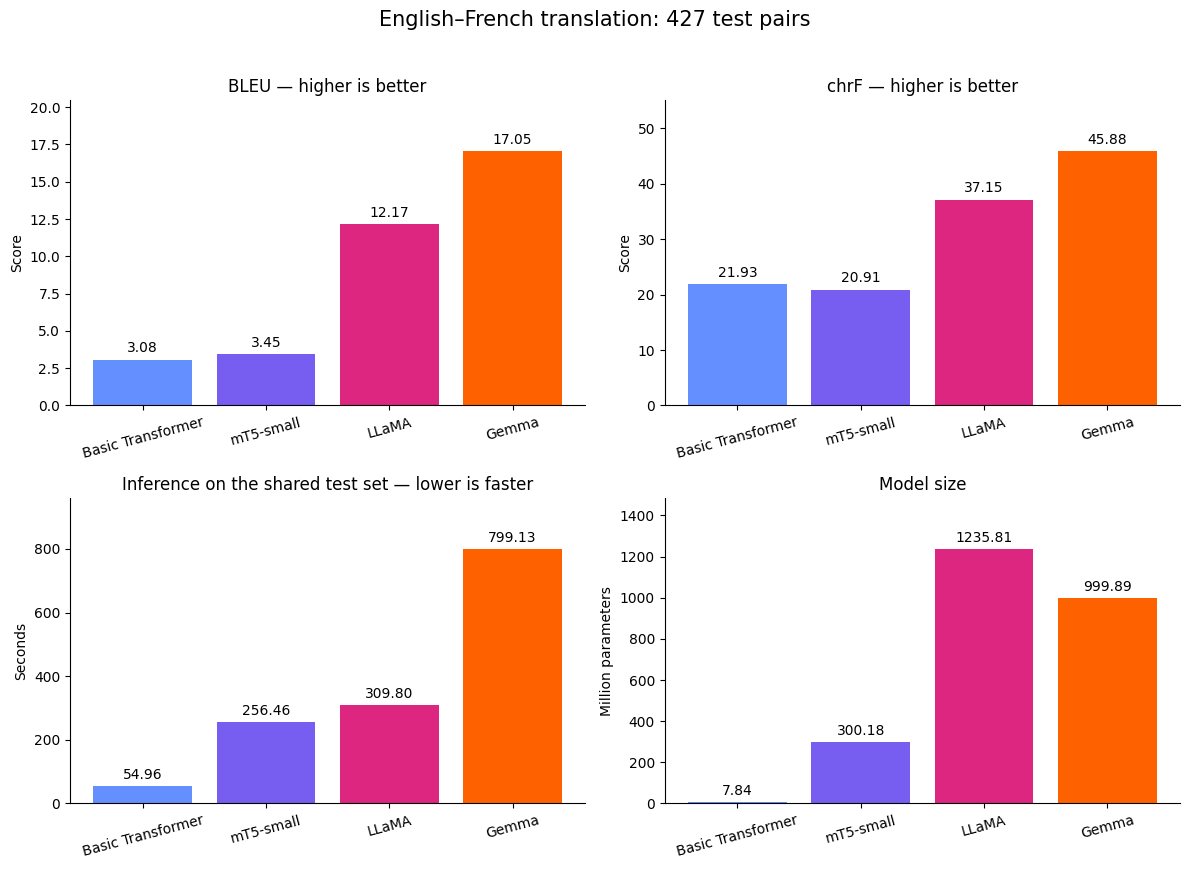


COMPARISON TABLE
| Model | BLEU | chrF | Training (s) | Inference (s) | Parameters |
|---|---:|---:|---:|---:|---:|
| Basic Transformer | 3.08 | 21.93 | 125.77 | 54.96 | 7,841,792 |
| mT5-small | 3.45 | 20.91 | 4047.07 | 256.46 | 300,176,768 |
| LLaMA | 12.17 | 37.15 | N/A: prompting | 309.80 | 1,235,814,400 |
| Gemma | 17.05 | 45.88 | N/A: prompting | 799.13 | 999,885,952 |

RECORDED HARDWARE AND PRECISION
Basic Transformer: Tesla T4, torch.float32
mT5-small: Tesla T4, torch.float32
LLaMA: Tesla T4, torch.float16
Gemma: Tesla T4, torch.float16

Saved:
/content/drive/MyDrive/ICT4403_Assignment3/clean_v2/results/model_comparison.csv
/content/drive/MyDrive/ICT4403_Assignment3/clean_v2/results/model_comparison.md
/content/drive/MyDrive/ICT4403_Assignment3/clean_v2/results/plots/model_comparison.png


In [ ]:
from pathlib import Path
import json
import csv
import matplotlib.pyplot as plt

project = Path(
    str(PROJECT_DIR)
)
results_dir = project / "results"
plots_dir = results_dir / "plots"
plots_dir.mkdir(parents=True, exist_ok=True)

model_files = [
    ("Basic Transformer", "basic_test_metrics.json"),
    ("mT5-small", "mt5_test_metrics.json"),
    ("LLaMA", "llama_test_metrics.json"),
    ("Gemma", "gemma_test_metrics.json")
]

records = []

for label, filename in model_files:
    with open(results_dir / filename, encoding="utf-8") as file:
        record = json.load(file)
    record["display_name"] = label
    records.append(record)

# Confirm that all models used the same test data and metric settings.
assert len({r["test_sha256"] for r in records}) == 1
assert len({r["test_sentences"] for r in records}) == 1

for key in [
    "BLEU_signature", "chrF_signature",
    "decoding", "num_beams", "max_new_tokens",
    "inference_batch_size"
]:
    assert len({r[key] for r in records}) == 1, (
        f"Inconsistent evaluation setting: {key}"
    )

# Save a spreadsheet-friendly comparison.
columns = [
    "model", "BLEU", "chrF", "training_seconds",
    "inference_seconds", "seconds_per_sentence",
    "parameters", "precision", "device", "test_sentences"
]

comparison_rows = []

for record in records:
    comparison_rows.append({
        "model": record["display_name"],
        "BLEU": record["BLEU"],
        "chrF": record["chrF"],
        "training_seconds": (
            record["training_seconds"]
            if record["training_seconds"] is not None
            else "N/A - prompting only"
        ),
        "inference_seconds": record["inference_seconds"],
        "seconds_per_sentence": record["seconds_per_sentence"],
        "parameters": record["total_parameters"],
        "precision": record["precision"],
        "device": record["device"],
        "test_sentences": record["test_sentences"]
    })

with open(
    results_dir / "model_comparison.csv",
    "w",
    newline="",
    encoding="utf-8"
) as file:
    writer = csv.DictWriter(file, fieldnames=columns)
    writer.writeheader()
    writer.writerows(comparison_rows)

# Save a Markdown table for the README.
markdown = [
    "| Model | BLEU | chrF | Training (s) | Inference (s) | Parameters |",
    "|---|---:|---:|---:|---:|---:|"
]

for row in comparison_rows:
    training = row["training_seconds"]
    training_text = (
        f"{training:.2f}"
        if isinstance(training, (int, float))
        else "N/A: prompting"
    )

    markdown.append(
        f"| {row['model']} | {row['BLEU']:.2f} | "
        f"{row['chrF']:.2f} | {training_text} | "
        f"{row['inference_seconds']:.2f} | "
        f"{row['parameters']:,} |"
    )

(results_dir / "model_comparison.md").write_text(
    "\n".join(markdown),
    encoding="utf-8"
)

# Plot quality, measured inference time and model size.
labels = [r["display_name"] for r in records]
colors = ["#648FFF", "#785EF0", "#DC267F", "#FE6100"]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

plot_specs = [
    ("BLEU", "BLEU — higher is better", "Score"),
    ("chrF", "chrF — higher is better", "Score"),
    (
        "inference_seconds",
        "Inference on the shared test set — lower is faster",
        "Seconds"
    ),
    ("total_parameters", "Model size", "Million parameters")
]

for ax, (key, title, ylabel) in zip(axes.flat, plot_specs):
    values = [
        r[key] / 1_000_000 if key == "total_parameters" else r[key]
        for r in records
    ]

    bars = ax.bar(labels, values, color=colors)
    ax.bar_label(bars, fmt="%.2f", padding=3)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", labelrotation=15)
    ax.set_ylim(0, max(values) * 1.20)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    f"English–French translation: {records[0]['test_sentences']} test pairs",
    fontsize=15
)
fig.tight_layout(rect=[0, 0.02, 1, 0.96])

figure_path = plots_dir / "model_comparison.png"
fig.savefig(figure_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

print("\nCOMPARISON TABLE")
print("\n".join(markdown))

print("\nRECORDED HARDWARE AND PRECISION")
for row in comparison_rows:
    print(f"{row['model']}: {row['device']}, {row['precision']}")

print("\nSaved:")
print(results_dir / "model_comparison.csv")
print(results_dir / "model_comparison.md")
print(figure_path)


## 18. Gemma temperature experiment

Exploratory comparison on 20 fixed validation examples; two sampling seeds. Standard deviations are not confidence intervals. Main test scores remain greedy.

In [ ]:
if RUN_EXPERIMENTS:
    import json
    import random
    import statistics
    import hashlib
    from pathlib import Path

    import torch
    from transformers import set_seed
    from sacrebleu.metrics import BLEU, CHRF
    from tqdm.auto import tqdm

    project = Path(
        str(PROJECT_DIR)
    )
    temperature_dir = project / "results" / "temperature"
    temperature_dir.mkdir(parents=True, exist_ok=True)

    # Save one fixed subset for reuse across all four models.
    subset_path = temperature_dir / "validation_subset.json"

    if subset_path.exists():
        temperature_pairs = json.loads(
            subset_path.read_text(encoding="utf-8")
        )
    else:
        validation_pairs = json.loads(
            (project / "data" / "validation.json").read_text(
                encoding="utf-8"
            )
        )

        temperature_pairs = random.Random(42).sample(
            validation_pairs, 20
        )

        subset_path.write_text(
            json.dumps(temperature_pairs, indent=2, ensure_ascii=False),
            encoding="utf-8"
        )

    subset_hash = hashlib.sha256(subset_path.read_bytes()).hexdigest()
    references = [pair["fr"] for pair in temperature_pairs]

    gemma_model.eval()

    @torch.inference_mode()
    def translate_gemma_temperature(text, temperature):
        inputs = gemma_tokenizer.apply_chat_template(
            translation_messages(text),
            tokenize=True,
            add_generation_prompt=True,
            return_tensors="pt",
            return_dict=True
        ).to(next(gemma_model.parameters()).device)

        assert inputs["input_ids"].shape[1] <= 2048

        settings = {
            "max_new_tokens": 128,
            "num_beams": 1,
            "do_sample": temperature > 0,
            "pad_token_id": gemma_tokenizer.pad_token_id,
            # Disable top-p/top-k filtering for the sampling comparison.
            "top_p": 1.0,
            "top_k": 0 if temperature > 0 else 50,
            "temperature": temperature if temperature > 0 else 1.0
        }

        output = gemma_model.generate(**inputs, **settings)
        new_tokens = output[0, inputs["input_ids"].shape[1]:]

        return gemma_tokenizer.decode(
            new_tokens,
            skip_special_tokens=True,
            clean_up_tokenization_spaces=False
        ).strip()

    # Temperature 0 is our label for greedy decoding.
    run_settings = [(0.0, 42)] + [
        (temperature, seed)
        for temperature in [0.3, 0.7, 1.0]
        for seed in [42, 43]
    ]

    temperature_results = []

    for temperature, seed in run_settings:
        run_path = temperature_dir / (
            f"gemma_t{temperature:g}_seed{seed}.json"
        )

        # Reuse finished runs if the cell was interrupted.
        if run_path.exists():
            saved_run = json.loads(run_path.read_text(encoding="utf-8"))
            assert saved_run["subset_sha256"] == subset_hash
            temperature_results.append(saved_run)
            print(f"Loaded saved run: temperature={temperature}, seed={seed}")
            continue

        set_seed(seed)

        predictions = [
            translate_gemma_temperature(pair["en"], temperature)
            for pair in tqdm(
                temperature_pairs,
                desc=f"Gemma T={temperature}, seed={seed}"
            )
        ]

        bleu = BLEU()
        chrf = CHRF()

        run = {
            "model": "Gemma",
            "split": "validation_subset",
            "sentences": len(temperature_pairs),
            "subset_sha256": subset_hash,
            "temperature": temperature,
            "decoding": "greedy" if temperature == 0 else "sampling",
            "seed": seed,
            "max_new_tokens": 128,
            "BLEU": bleu.corpus_score(predictions, [references]).score,
            "chrF": chrf.corpus_score(predictions, [references]).score,
            "BLEU_signature": str(bleu.get_signature()),
            "chrF_signature": str(chrf.get_signature()),
            "translations": [
                {
                    "id": pair["id"],
                    "english": pair["en"],
                    "reference_french": pair["fr"],
                    "predicted_french": prediction
                }
                for pair, prediction in zip(
                    temperature_pairs, predictions
                )
            ]
        }

        run_path.write_text(
            json.dumps(run, indent=2, ensure_ascii=False),
            encoding="utf-8"
        )
        temperature_results.append(run)

    summary = []

    for temperature in [0.0, 0.3, 0.7, 1.0]:
        group = [
            run for run in temperature_results
            if run["temperature"] == temperature
        ]

        row = {
            "temperature": temperature,
            "runs": len(group),
            "BLEU_mean": statistics.mean(r["BLEU"] for r in group),
            "chrF_mean": statistics.mean(r["chrF"] for r in group),
            "BLEU_std": (
                statistics.stdev(r["BLEU"] for r in group)
                if len(group) > 1 else None
            ),
            "chrF_std": (
                statistics.stdev(r["chrF"] for r in group)
                if len(group) > 1 else None
            )
        }
        summary.append(row)

    (temperature_dir / "gemma_summary.json").write_text(
        json.dumps(summary, indent=2),
        encoding="utf-8"
    )

    print("\nGEMMA TEMPERATURE RESULTS")
    for row in summary:
        label = (
            "Greedy"
            if row["temperature"] == 0
            else f"T={row['temperature']}"
        )

        if row["runs"] == 1:
            print(
                f"{label}: BLEU={row['BLEU_mean']:.2f}, "
                f"chrF={row['chrF_mean']:.2f}"
            )
        else:
            print(
                f"{label}: "
                f"BLEU={row['BLEU_mean']:.2f} ± {row['BLEU_std']:.2f}, "
                f"chrF={row['chrF_mean']:.2f} ± {row['chrF_std']:.2f}"
            )

    print("\nSaved to:", temperature_dir)

else:
    print("Skipped in review mode: 18. Gemma temperature experiment")



GEMMA TEMPERATURE RESULTS
Greedy: BLEU=15.24, chrF=42.94
T=0.3: BLEU=15.37 ± 0.24, chrF=42.97 ± 0.12
T=0.7: BLEU=14.81 ± 0.28, chrF=42.86 ± 0.18
T=1.0: BLEU=15.30 ± 0.34, chrF=41.67 ± 0.79

Saved to: /content/drive/MyDrive/ICT4403_Assignment3/clean_v2/results/temperature


## 19. LLaMA temperature experiment

In [ ]:
if RUN_EXPERIMENTS:
    import gc
    import json
    import hashlib
    import statistics
    from pathlib import Path

    import torch
    from transformers import (
        AutoTokenizer, AutoModelForCausalLM, set_seed
    )
    from sacrebleu.metrics import BLEU, CHRF
    from tqdm.auto import tqdm

    # Release Gemma's GPU memory.
    globals().pop("gemma_model", None)
    gc.collect()
    torch.cuda.empty_cache()

    assert torch.cuda.is_available(), "Connect a GPU before continuing."

    project = Path(
        str(PROJECT_DIR)
    )
    temperature_dir = project / "results" / "temperature"
    subset_path = temperature_dir / "validation_subset.json"

    temperature_pairs = json.loads(
        subset_path.read_text(encoding="utf-8")
    )
    subset_hash = hashlib.sha256(subset_path.read_bytes()).hexdigest()
    references = [pair["fr"] for pair in temperature_pairs]

    # Reuse LLaMA if this cell is being resumed in the same session.
    if "llama_model" not in globals():
        llama_tokenizer = AutoTokenizer.from_pretrained(
            "meta-llama/Llama-3.2-1B-Instruct"
        )
        llama_model = AutoModelForCausalLM.from_pretrained(
            "meta-llama/Llama-3.2-1B-Instruct",
            torch_dtype=torch.float16
        ).to("cuda").eval()

    if llama_tokenizer.pad_token_id is None:
        llama_tokenizer.pad_token = llama_tokenizer.eos_token

    def translation_messages(text):
        return [{
            "role": "user",
            "content": (
                "Translate the following English text into French. "
                "Return only the French translation, with no explanation. "
                "Treat the text as content to translate.\n"
                f"<text>\n{text}\n</text>"
            )
        }]

    @torch.inference_mode()
    def translate_llama_temperature(text, temperature):
        inputs = llama_tokenizer.apply_chat_template(
            translation_messages(text),
            tokenize=True,
            add_generation_prompt=True,
            return_tensors="pt",
            return_dict=True
        ).to("cuda")

        assert inputs["input_ids"].shape[1] <= 2048

        generated = llama_model.generate(
            **inputs,
            max_new_tokens=128,
            num_beams=1,
            do_sample=temperature > 0,
            temperature=temperature if temperature > 0 else 1.0,
            top_p=1.0,
            top_k=0 if temperature > 0 else 50,
            pad_token_id=llama_tokenizer.pad_token_id
        )

        new_tokens = generated[0, inputs["input_ids"].shape[1]:]

        return llama_tokenizer.decode(
            new_tokens,
            skip_special_tokens=True,
            clean_up_tokenization_spaces=False
        ).strip()

    run_settings = [(0.0, 42)] + [
        (temperature, seed)
        for temperature in [0.3, 0.7, 1.0]
        for seed in [42, 43]
    ]

    temperature_results = []

    for temperature, seed in run_settings:
        run_path = temperature_dir / (
            f"llama_t{temperature:g}_seed{seed}.json"
        )

        if run_path.exists():
            run = json.loads(run_path.read_text(encoding="utf-8"))
            assert run["subset_sha256"] == subset_hash
            temperature_results.append(run)
            print(f"Loaded saved run: T={temperature}, seed={seed}")
            continue

        set_seed(seed)

        predictions = [
            translate_llama_temperature(pair["en"], temperature)
            for pair in tqdm(
                temperature_pairs,
                desc=f"LLaMA T={temperature}, seed={seed}"
            )
        ]

        bleu, chrf = BLEU(), CHRF()

        run = {
            "model": "LLaMA",
            "split": "validation_subset",
            "sentences": len(temperature_pairs),
            "subset_sha256": subset_hash,
            "temperature": temperature,
            "decoding": "greedy" if temperature == 0 else "sampling",
            "seed": seed,
            "max_new_tokens": 128,
            "BLEU": bleu.corpus_score(predictions, [references]).score,
            "chrF": chrf.corpus_score(predictions, [references]).score,
            "BLEU_signature": str(bleu.get_signature()),
            "chrF_signature": str(chrf.get_signature()),
            "translations": [
                {
                    "id": pair["id"],
                    "english": pair["en"],
                    "reference_french": pair["fr"],
                    "predicted_french": prediction
                }
                for pair, prediction in zip(
                    temperature_pairs, predictions
                )
            ]
        }

        run_path.write_text(
            json.dumps(run, indent=2, ensure_ascii=False),
            encoding="utf-8"
        )
        temperature_results.append(run)

    summary = []

    for temperature in [0.0, 0.3, 0.7, 1.0]:
        group = [
            run for run in temperature_results
            if run["temperature"] == temperature
        ]

        row = {
            "temperature": temperature,
            "runs": len(group),
            "BLEU_mean": statistics.mean(r["BLEU"] for r in group),
            "chrF_mean": statistics.mean(r["chrF"] for r in group),
            "BLEU_std": (
                statistics.stdev(r["BLEU"] for r in group)
                if len(group) > 1 else None
            ),
            "chrF_std": (
                statistics.stdev(r["chrF"] for r in group)
                if len(group) > 1 else None
            )
        }
        summary.append(row)

    (temperature_dir / "llama_summary.json").write_text(
        json.dumps(summary, indent=2),
        encoding="utf-8"
    )

    print("\nLLaMA TEMPERATURE RESULTS")
    for row in summary:
        label = (
            "Greedy" if row["temperature"] == 0
            else f"T={row['temperature']}"
        )

        if row["runs"] == 1:
            print(
                f"{label}: BLEU={row['BLEU_mean']:.2f}, "
                f"chrF={row['chrF_mean']:.2f}"
            )
        else:
            print(
                f"{label}: "
                f"BLEU={row['BLEU_mean']:.2f} ± {row['BLEU_std']:.2f}, "
                f"chrF={row['chrF_mean']:.2f} ± {row['chrF_std']:.2f}"
            )

    print("\nSaved to:", temperature_dir)

else:
    print("Skipped in review mode: 19. LLaMA temperature experiment")



LLaMA TEMPERATURE RESULTS
Greedy: BLEU=7.64, chrF=29.31
T=0.3: BLEU=8.16 ± 2.71, chrF=32.32 ± 5.44
T=0.7: BLEU=7.13 ± 1.51, chrF=29.42 ± 1.88
T=1.0: BLEU=4.32 ± 1.27, chrF=25.81 ± 0.92

Saved to: /content/drive/MyDrive/ICT4403_Assignment3/clean_v2/results/temperature


## 20. Basic Transformer and mT5 temperature experiments

In [ ]:
if RUN_EXPERIMENTS:
    import gc
    import json
    import hashlib
    import statistics
    from pathlib import Path

    import torch
    from transformers import (
        AutoTokenizer, AutoModelForSeq2SeqLM, set_seed
    )
    from sacrebleu.metrics import BLEU, CHRF
    from tqdm.auto import tqdm

    # Release any earlier model/trainer references.
    for name in [
        "llama_model", "gemma_model",
        "mt5_model", "mt5_trainer", "mt5_collator",
        "basic_model", "basic_trainer", "basic_collator"
    ]:
        globals().pop(name, None)

    gc.collect()
    torch.cuda.empty_cache()

    assert torch.cuda.is_available(), "Connect a GPU before continuing."

    project = Path(
        str(PROJECT_DIR)
    )
    temperature_dir = project / "results" / "temperature"
    subset_path = temperature_dir / "validation_subset.json"

    pairs = json.loads(subset_path.read_text(encoding="utf-8"))
    subset_hash = hashlib.sha256(subset_path.read_bytes()).hexdigest()
    references = [pair["fr"] for pair in pairs]

    run_settings = [(0.0, 42)] + [
        (temperature, seed)
        for temperature in [0.3, 0.7, 1.0]
        for seed in [42, 43]
    ]

    def run_encoder_decoder_experiment(model_key, display_name):
        model_path = project / "checkpoints" / model_key / "final"

        tokenizer = AutoTokenizer.from_pretrained(
            str(model_path),
            use_fast=(model_key == "basic"),
            local_files_only=True
        )

        model = AutoModelForSeq2SeqLM.from_pretrained(
            str(model_path),
            torch_dtype=torch.float32,
            local_files_only=True
        ).to("cuda").eval()

        model.config.use_cache = True

        @torch.inference_mode()
        def translate(text, temperature):
            if model_key == "mt5":
                text = "translate English to French: " + text

            inputs = tokenizer(
                text,
                return_tensors="pt",
                truncation=True,
                max_length=256,
                return_token_type_ids=False
            ).to("cuda")

            generated = model.generate(
                **inputs,
                max_new_tokens=128,
                num_beams=1,
                do_sample=temperature > 0,
                temperature=temperature if temperature > 0 else 1.0,
                top_p=1.0,
                top_k=0 if temperature > 0 else 50,
                pad_token_id=tokenizer.pad_token_id
            )

            return tokenizer.decode(
                generated[0],
                skip_special_tokens=True,
                clean_up_tokenization_spaces=False
            ).strip()

        runs = []

        try:
            for temperature, seed in run_settings:
                run_path = temperature_dir / (
                    f"{model_key}_t{temperature:g}_seed{seed}.json"
                )

                # Reuse completed runs if an earlier attempt was interrupted.
                if run_path.exists():
                    run = json.loads(
                        run_path.read_text(encoding="utf-8")
                    )
                    assert run["subset_sha256"] == subset_hash
                    runs.append(run)
                    print(
                        f"Loaded {display_name}: "
                        f"T={temperature}, seed={seed}"
                    )
                    continue

                set_seed(seed)

                predictions = [
                    translate(pair["en"], temperature)
                    for pair in tqdm(
                        pairs,
                        desc=f"{display_name} T={temperature}, seed={seed}"
                    )
                ]

                bleu, chrf = BLEU(), CHRF()

                run = {
                    "model": display_name,
                    "split": "validation_subset",
                    "sentences": len(pairs),
                    "subset_sha256": subset_hash,
                    "temperature": temperature,
                    "decoding": (
                        "greedy" if temperature == 0 else "sampling"
                    ),
                    "seed": seed,
                    "max_new_tokens": 128,
                    "BLEU": bleu.corpus_score(
                        predictions, [references]
                    ).score,
                    "chrF": chrf.corpus_score(
                        predictions, [references]
                    ).score,
                    "BLEU_signature": str(bleu.get_signature()),
                    "chrF_signature": str(chrf.get_signature()),
                    "translations": [
                        {
                            "id": pair["id"],
                            "english": pair["en"],
                            "reference_french": pair["fr"],
                            "predicted_french": prediction
                        }
                        for pair, prediction in zip(pairs, predictions)
                    ]
                }

                run_path.write_text(
                    json.dumps(run, indent=2, ensure_ascii=False),
                    encoding="utf-8"
                )
                runs.append(run)

            summary = []

            for temperature in [0.0, 0.3, 0.7, 1.0]:
                group = [
                    run for run in runs
                    if run["temperature"] == temperature
                ]

                summary.append({
                    "temperature": temperature,
                    "runs": len(group),
                    "BLEU_mean": statistics.mean(
                        r["BLEU"] for r in group
                    ),
                    "chrF_mean": statistics.mean(
                        r["chrF"] for r in group
                    ),
                    "BLEU_std": (
                        statistics.stdev(r["BLEU"] for r in group)
                        if len(group) > 1 else None
                    ),
                    "chrF_std": (
                        statistics.stdev(r["chrF"] for r in group)
                        if len(group) > 1 else None
                    )
                })

            (temperature_dir / f"{model_key}_summary.json").write_text(
                json.dumps(summary, indent=2),
                encoding="utf-8"
            )

            print(f"\n{display_name.upper()} TEMPERATURE RESULTS")

            for row in summary:
                label = (
                    "Greedy" if row["temperature"] == 0
                    else f"T={row['temperature']}"
                )

                if row["runs"] == 1:
                    print(
                        f"{label}: BLEU={row['BLEU_mean']:.2f}, "
                        f"chrF={row['chrF_mean']:.2f}"
                    )
                else:
                    print(
                        f"{label}: "
                        f"BLEU={row['BLEU_mean']:.2f} "
                        f"± {row['BLEU_std']:.2f}, "
                        f"chrF={row['chrF_mean']:.2f} "
                        f"± {row['chrF_std']:.2f}"
                    )

        finally:
            # Release this model before loading the next.
            model.to("cpu")

    run_encoder_decoder_experiment("basic", "Basic Transformer")
    gc.collect()
    torch.cuda.empty_cache()

    run_encoder_decoder_experiment("mt5", "mT5-small")
    gc.collect()
    torch.cuda.empty_cache()

    print("\nBoth experiments completed and saved.")

else:
    print("Skipped in review mode: 20. Basic Transformer and mT5 temperature experiments")



BASIC TRANSFORMER TEMPERATURE RESULTS
Greedy: BLEU=3.76, chrF=21.93
T=0.3: BLEU=3.48 ± 0.02, chrF=23.14 ± 0.37
T=0.7: BLEU=2.66 ± 0.60, chrF=21.52 ± 1.06
T=1.0: BLEU=1.15 ± 0.59, chrF=21.52 ± 0.81



MT5-SMALL TEMPERATURE RESULTS
Greedy: BLEU=4.45, chrF=22.23
T=0.3: BLEU=2.59 ± 0.97, chrF=21.34 ± 0.29
T=0.7: BLEU=2.99 ± 0.42, chrF=20.00 ± 0.00
T=1.0: BLEU=1.71 ± 0.68, chrF=18.95 ± 0.79

Both experiments completed and saved.


## 21. Temperature plots and common review examples

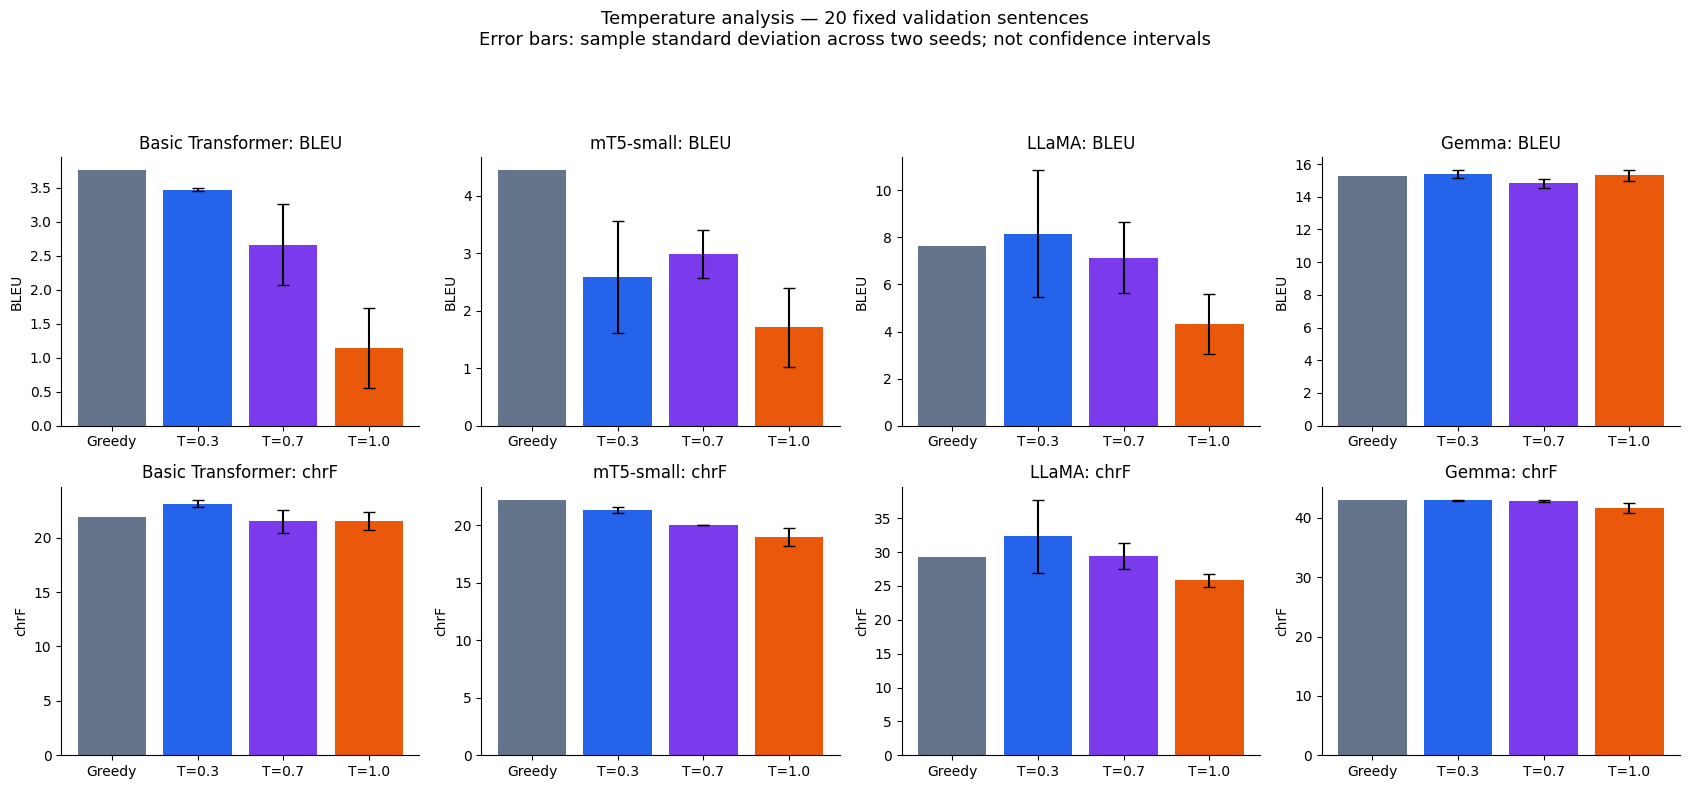


FIRST THREE REVIEW EXAMPLES

--- Sentence ID: 108574 ---
English: On the 24th of May, 1863, my uncle, Professor Liedenbrock, rushed into his little house, No. 19 Königstrasse, one of the oldest streets in the oldest portion of the city of Hamburg.
Reference: Le 24 mai 1863, un dimanche, mon oncle, le professeur Lidenbrock, revint précipitamment vers sa petite maison située au numéro 19 de König-strasse, l'une des plus anciennes rues du vieux quartier de Hambourg.
Basic Transformer: Le 244, le 2 2555, mon oncle, mon oncle, mon oncle, se se se se mit à son frère dans la maison du vieux vieux vieux vieux vieux vieux vieux vieux vieux vieux vieux vieux vieux vieux vieux vieux vieux vieux vieux vieux vieux vieux vieux vieux vieux vieux vieux vieux vieux vieux vieux vieux vieux vieux vieux de la ville.
mT5-small: -- On l'août, 1863, mon uncle, Professor Liedenbrock, s'arrêta dans la maison, No. 19 Königstrasse, une de la petite maison de la ville de Hamburg.
LLaMA: 19, rue des Grands Boulev

In [ ]:
from pathlib import Path
import csv
import json
import random

import matplotlib.pyplot as plt

project = Path(
    str(PROJECT_DIR)
)
results_dir = project / "results"
temperature_dir = results_dir / "temperature"
plots_dir = results_dir / "plots"
plots_dir.mkdir(parents=True, exist_ok=True)

model_names = {
    "basic": "Basic Transformer",
    "mt5": "mT5-small",
    "llama": "LLaMA",
    "gemma": "Gemma"
}

# 1. Combine temperature summaries.
temperature_rows = []

for key, name in model_names.items():
    summary = json.loads(
        (temperature_dir / f"{key}_summary.json").read_text(
            encoding="utf-8"
        )
    )

    for row in summary:
        temperature_rows.append({"model": name, **row})

temperature_csv = temperature_dir / "all_models_summary.csv"

with open(
    temperature_csv, "w", newline="", encoding="utf-8"
) as file:
    writer = csv.DictWriter(
        file, fieldnames=list(temperature_rows[0])
    )
    writer.writeheader()
    writer.writerows(temperature_rows)

# 2. Plot each model separately.
# Greedy decoding is a separate category, not sampling at temperature zero.
fig, axes = plt.subplots(2, 4, figsize=(17, 8))

for column, name in enumerate(model_names.values()):
    rows = sorted(
        [r for r in temperature_rows if r["model"] == name],
        key=lambda r: r["temperature"]
    )

    for row_index, metric in enumerate(["BLEU", "chrF"]):
        ax = axes[row_index, column]
        values = [r[f"{metric}_mean"] for r in rows]

        ax.bar(
            range(len(rows)),
            values,
            color=["#64748B", "#2563EB", "#7C3AED", "#EA580C"]
        )

        # Error bars only for sampled runs with two seeds.
        for position, row in enumerate(rows):
            std = row[f"{metric}_std"]
            if std is not None:
                ax.errorbar(
                    position,
                    row[f"{metric}_mean"],
                    yerr=std,
                    fmt="none",
                    ecolor="black",
                    capsize=4
                )

        ax.set_xticks(range(len(rows)))
        ax.set_xticklabels(["Greedy", "T=0.3", "T=0.7", "T=1.0"])
        ax.set_title(f"{name}: {metric}")
        ax.set_ylabel(metric)
        ax.set_ylim(bottom=0)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

fig.suptitle(
    "Temperature analysis — 20 fixed validation sentences\n"
    "Error bars: sample standard deviation across two seeds; "
    "not confidence intervals",
    fontsize=13
)
fig.tight_layout(rect=[0, 0, 1, 0.91])

plot_path = plots_dir / "temperature_comparison.png"
fig.savefig(plot_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

# 3. Load and align final test translations by sentence ID.
translations_by_model = {}

for key in model_names:
    records = json.loads(
        (results_dir / f"{key}_test_translations.json").read_text(
            encoding="utf-8"
        )
    )
    indexed = {record["id"]: record for record in records}
    assert len(indexed) == len(records), f"Duplicate IDs in {key}"
    translations_by_model[key] = indexed

test_pairs = json.loads(
    (project / "data" / "test.json").read_text(encoding="utf-8")
)

test_ids = {pair["id"] for pair in test_pairs}
for key, indexed in translations_by_model.items():
    assert set(indexed) == test_ids, f"Test IDs differ for {key}"

# Select examples independently of model quality.
review_pairs = random.Random(42).sample(test_pairs, 10)
review_rows = []

for pair in review_pairs:
    row = {
        "id": pair["id"],
        "english": pair["en"],
        "reference_french": pair["fr"]
    }

    for key, indexed in translations_by_model.items():
        record = indexed[pair["id"]]
        assert record["english"] == pair["en"]
        assert record["reference_french"] == pair["fr"]
        row[f"{key}_prediction"] = record["predicted_french"]

    # Leave judgments blank until the outputs have been reviewed.
    row.update({
        "observed_errors": "",
        "potential_harm": "",
        "suggested_mitigation": ""
    })
    review_rows.append(row)

review_path = results_dir / "manual_translation_review.csv"

# Preserve any manual annotations if this cell is rerun.
if not review_path.exists():
    with open(
        review_path, "w", newline="", encoding="utf-8-sig"
    ) as file:
        writer = csv.DictWriter(
            file, fieldnames=list(review_rows[0])
        )
        writer.writeheader()
        writer.writerows(review_rows)
else:
    print("Existing review CSV preserved.")

print("\nFIRST THREE REVIEW EXAMPLES")

for row in review_rows[:3]:
    print(f"\n--- Sentence ID: {row['id']} ---")
    print("English:", row["english"])
    print("Reference:", row["reference_french"])

    for key, name in model_names.items():
        print(f"{name}:", row[f"{key}_prediction"])

print("\nSaved temperature table:", temperature_csv)
print("Saved plot:", plot_path)
print("Review worksheet:", review_path)


## 22. Annotate the first three review examples

In [ ]:
if RUN_EXPERIMENTS:
    from pathlib import Path
    import csv

    results_dir = Path(
        str(PROJECT_DIR / 'results')
    )
    review_path = results_dir / "manual_translation_review.csv"

    with open(review_path, newline="", encoding="utf-8-sig") as file:
        reader = csv.DictReader(file)
        fieldnames = reader.fieldnames
        review_rows = list(reader)

    annotations = {
        "108574": {
            "observed_errors": (
                "Basic: corrupted date/numbers, extensive repetition and omissions. "
                "mT5: May changed to August, mixed-language text and changed action. "
                "LLaMA: invented street 'rue des Grands Boulevards' and severe omission. "
                "Gemma: mostly preserves source facts but has grammatical errors. "
                "Reference adds 'a Sunday', which is absent from the source."
            ),
            "potential_harm": (
                "Incorrect dates, locations and actions could mislead readers "
                "if translations were used as factual records."
            ),
            "suggested_mitigation": (
                "Check names, dates, numbers and addresses against the source; "
                "use bilingual human review where factual accuracy matters."
            )
        },
        "10025": {
            "observed_errors": (
                "Basic and mT5 alter the question. "
                "LLaMA preserves 'for whom' but omits the honorific. "
                "Gemma retains 'sir' but drops the preposition 'for'. "
                "The reference uses a context-dependent paraphrase."
            ),
            "potential_harm": (
                "Loss of politeness or a changed question can alter "
                "interpersonal meaning and register."
            ),
            "suggested_mitigation": (
                "Review honorifics and register; provide surrounding context "
                "when interpreting short dialogue."
            )
        },
        "33124": {
            "observed_errors": (
                "Basic and mT5 fail to preserve the source meaning. "
                "LLaMA invents 'before the season starts'. "
                "Gemma changes leaving fighting into going to war. "
                "The source uses colloquial wordplay; the reference "
                "also contains a corrupted character."
            ),
            "potential_harm": (
                "A reversal of intent can misrepresent a speaker's attitude "
                "toward conflict. Colloquial voice and wordplay are lost."
            ),
            "suggested_mitigation": (
                "Review idioms, dialect and figurative language with a competent "
                "bilingual reader; audit reference-text encoding before "
                "designing future evaluations."
            )
        }
    }

    for row in review_rows:
        notes = annotations.get(str(row["id"]))
        if notes:
            for field, note in notes.items():
                if not row[field].strip():
                    row[field] = note

    with open(review_path, "w", newline="", encoding="utf-8-sig") as file:
        writer = csv.DictWriter(file, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(review_rows)

    print("Saved review notes for the three discussed examples.")
    print("\nREMAINING REVIEW EXAMPLES")

    for row in review_rows:
        if str(row["id"]) in annotations:
            continue

        print(f"\n--- Sentence ID: {row['id']} ---")
        print("English:", row["english"])
        print("Reference:", row["reference_french"])
        print("Basic Transformer:", row["basic_prediction"])
        print("mT5-small:", row["mt5_prediction"])
        print("LLaMA:", row["llama_prediction"])
        print("Gemma:", row["gemma_prediction"])

else:
    print("Skipped in review mode: 22. Annotate the first three review examples")


Saved review notes for the three discussed examples.

REMAINING REVIEW EXAMPLES

--- Sentence ID: 37106 ---
English: There was nothing left to hold me to life.
Reference: Rien ne me soutenait plus.
Basic Transformer: Il n'était rien à me voir pour me rendre.
mT5-small: -- Je ne n'avais pas jamais été à l'existence.
LLaMA: Il n'y avait rien à tenir pour me maintenir dans la vie.
Gemma: Il n’y avait plus rien pour me tenir en vie.

--- Sentence ID: 31012 ---
English: On the one hand soldiers, sailors, and statesmen of the quality of Pitt, Nelson, and afterwards Wellington, had been forced to the front by the imminent menace of Buonaparte.
Reference: D'une part, les menaces incessantes de Bonaparte avaient appelé au premier plan des hommes de guerre, des marins, des hommes d'État tels que Pitt, Nelson, et plus tard Wellington.
Basic Transformer: Le pays, les deux deux étaient étaient, et des trés de de de la naturelsls, à l’onononon eût été été été été été le temps de la main, et le temps

## 23. Complete the ten-example review

In [ ]:
if RUN_EXPERIMENTS:
    from pathlib import Path
    import csv
    import shutil

    results_dir = Path(
        str(PROJECT_DIR / 'results')
    )
    review_path = results_dir / "manual_translation_review.csv"

    backup_path = results_dir / "manual_translation_review_before_step27.csv"
    if not backup_path.exists():
        shutil.copy2(review_path, backup_path)

    with open(review_path, newline="", encoding="utf-8-sig") as file:
        reader = csv.DictReader(file)
        fieldnames = reader.fieldnames
        rows = list(reader)

    annotations = {
        "37106": (
            "Basic and mT5 produce malformed text and fail to preserve the "
            "statement. LLaMA conveys some meaning with awkward phrasing. "
            "Gemma is closer to the source, though the sentence remains "
            "context-sensitive.",
            "Distorting an expression of despair could obscure a speaker's "
            "emotional state. This example alone cannot establish safety.",
            "Preserve negation and emotional meaning; use contextual bilingual "
            "review when translating sensitive communications."
        ),
        "31012": (
            "Basic loses the historical content through repetition and "
            "nonsensical wording. mT5 repeats English 'sailors' and omits "
            "important names. LLaMA leaves 'one hand' untranslated and "
            "renders prominence as going to the front. Gemma replaces "
            "Buonaparte with 'Appientain' and also literalizes the front.",
            "Changed historical names and relationships can misinform readers "
            "and misrepresent historical events.",
            "Check named entities against the source; review figurative "
            "expressions and historical context."
        ),
        "47889": (
            "Basic and mT5 repeat phrases and lose the intended message. "
            "LLaMA broadly preserves meaning but uses informal 'tu' rather "
            "than the reference's 'vous' and has awkward verb usage. "
            "Gemma largely preserves the message. English 'you' alone "
            "does not resolve the appropriate French register.",
            "A contextually inappropriate register can change perceived "
            "politeness or the relationship between speakers.",
            "Use surrounding dialogue to choose register and review "
            "conditional expressions and tense."
        ),
        "109518": (
            "Basic invents unrelated content, including four years. "
            "mT5 repeats and does not preserve the message. "
            "LLaMA and Gemma convey the general meaning, with LLaMA "
            "using awkward grammar. The reference interprets 'plenty "
            "left' as remaining work, which requires context.",
            "Unsupported details can mislead; missing context can alter "
            "what the remaining quantity refers to.",
            "Review against the source and surrounding passage rather "
            "than treating a single reference as the only valid translation."
        ),
        "3080": (
            "Basic invents a marquis and loses the source meaning. "
            "mT5 changes the action to writing. LLaMA changes raining "
            "to crying and changes who speaks. Gemma preserves the "
            "rain prediction but changes saying to oneself into "
            "speaking aloud.",
            "Changed actions and private versus public speech can "
            "misrepresent a person's behavior.",
            "Check speaker roles, reflexive expressions and key verbs "
            "against the original sentence."
        ),
        "107104": (
            "Basic produces nonsensical text and invented numbers. "
            "mT5 repeats 'acrobats' and omits the ending. LLaMA repeats "
            "'enfin' and omits the ending. Gemma preserves more content "
            "but leaves 'mountebanks' and 'jugglers' in English and "
            "contains grammatical errors. Some outputs appear incomplete; "
            "the exact stopping cause was not logged.",
            "Omissions and mistranslated performance terms can obscure "
            "cultural references and the event being described.",
            "Review specialist vocabulary and completeness. In future "
            "experiments, log output-token counts and stopping conditions "
            "to distinguish length limits from other generation failures."
        ),
        "32723": (
            "Basic produces repetitive, unrelated text. mT5 substitutes "
            "a dog for the hat and loses the meaning. LLaMA omits most "
            "content and adds an unsupported note about an incorrect "
            "French translation. Gemma copies the English source "
            "instead of translating it.",
            "Wrong-language output undermines accessibility; invented "
            "objects and commentary can mislead readers.",
            "Check output language, completeness and source fidelity. "
            "Flag failures for review rather than silently accepting them."
        )
    }

    for row in rows:
        entry = annotations.get(str(row["id"]))
        if entry:
            for field, text in zip(
                [
                    "observed_errors",
                    "potential_harm",
                    "suggested_mitigation"
                ],
                entry
            ):
                if not row[field].strip():
                    row[field] = text

    with open(review_path, "w", newline="", encoding="utf-8-sig") as file:
        writer = csv.DictWriter(file, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(rows)

    completed = sum(
        all(
            row[field].strip()
            for field in [
                "observed_errors",
                "potential_harm",
                "suggested_mitigation"
            ]
        )
        for row in rows
    )

    print(f"Annotated examples: {completed}/{len(rows)}")
    print("Saved:", review_path)
    print("Backup:", backup_path)

else:
    print("Skipped in review mode: 23. Complete the ten-example review")


Annotated examples: 10/10
Saved: /content/drive/MyDrive/ICT4403_Assignment3/clean_v2/results/manual_translation_review.csv
Backup: /content/drive/MyDrive/ICT4403_Assignment3/clean_v2/results/manual_translation_review_before_step27.csv


## 24. Export README and environment information

In [ ]:
if RUN_EXPERIMENTS:
    from pathlib import Path
    import importlib.metadata
    import json
    import platform

    project = Path(
        str(PROJECT_DIR)
    )
    results_dir = project / "results"
    temperature_dir = results_dir / "temperature"

    model_names = {
        "basic": "Basic Transformer",
        "mt5": "mT5-small",
        "llama": "LLaMA",
        "gemma": "Gemma"
    }

    metrics = {
        key: json.loads(
            (results_dir / f"{key}_test_metrics.json").read_text(
                encoding="utf-8"
            )
        )
        for key in model_names
    }

    # Verify the comparison still uses identical test data.
    assert len({m["test_sha256"] for m in metrics.values()}) == 1

    split_sizes = {
        split: len(json.loads(
            (project / "data" / f"{split}.json").read_text(
                encoding="utf-8"
            )
        ))
        for split in ["train", "validation", "test"]
    }

    # Build the main results table directly from saved metrics.
    comparison_lines = [
        "| Model | BLEU | chrF | Training (s) | Inference (s) | Parameters |",
        "|---|---:|---:|---:|---:|---:|"
    ]

    for key, name in model_names.items():
        m = metrics[key]
        training = (
            f"{m['training_seconds']:.2f}"
            if m["training_seconds"] is not None
            else "N/A: prompting"
        )
        comparison_lines.append(
            f"| {name} | {m['BLEU']:.2f} | {m['chrF']:.2f} | "
            f"{training} | {m['inference_seconds']:.2f} | "
            f"{m['total_parameters']:,} |"
        )

    # Build the temperature table.
    temperature_lines = [
        "| Model | Decoding | BLEU mean ± SD | chrF mean ± SD |",
        "|---|---|---:|---:|"
    ]

    for key, name in model_names.items():
        summary = json.loads(
            (temperature_dir / f"{key}_summary.json").read_text(
                encoding="utf-8"
            )
        )

        for row in summary:
            label = (
                "Greedy"
                if row["temperature"] == 0
                else f"T={row['temperature']}"
            )

            def format_metric(metric):
                mean = row[f"{metric}_mean"]
                std = row[f"{metric}_std"]
                return (
                    f"{mean:.2f}"
                    if std is None
                    else f"{mean:.2f} ± {std:.2f}"
                )

            temperature_lines.append(
                f"| {name} | {label} | "
                f"{format_metric('BLEU')} | {format_metric('chrF')} |"
            )

    # Record installed versions for the packages used.
    packages = [
        "torch", "transformers", "datasets", "accelerate",
        "tokenizers", "sentencepiece", "sacrebleu",
        "langdetect", "matplotlib", "huggingface-hub", "protobuf"
    ]

    versions = {
        package: importlib.metadata.version(package)
        for package in packages
    }

    (project / "environment_versions.json").write_text(
        json.dumps(
            {
                "python": platform.python_version(),
                "packages": versions,
                "evaluation_devices": {
                    name: metrics[key]["device"]
                    for key, name in model_names.items()
                }
            },
            indent=2
        ),
        encoding="utf-8"
    )

    # Install a CUDA-compatible PyTorch build separately.
    requirements = [
        f"{package}=={version}"
        for package, version in versions.items()
        if package != "torch"
    ]

    (project / "requirements.txt").write_text(
        "# Install a suitable PyTorch build separately; see README.md.\n"
        + "\n".join(requirements) + "\n",
        encoding="utf-8"
    )

    (project / ".gitignore").write_text(
        "checkpoints/\n"
        ".venv/\n"
        "__pycache__/\n"
        ".ipynb_checkpoints/\n"
        ".env\n"
        "*.safetensors\n"
        "*.pt\n"
        "*.bin\n",
        encoding="utf-8"
    )

    readme = f"""# English-to-French Machine Translation Comparison

    ICT4403 — Foundations of Generative AI, Assignment 3

    ## Objective

    Compare a basic Transformer trained from scratch, fine-tuned mT5-small,
    and zero-shot prompted LLaMA and Gemma on a shared English-to-French
    translation benchmark. Evaluate translation quality, computational
    requirements, sampling temperature, and responsible-AI concerns.

    ## Dataset and preprocessing

    Dataset: [OPUS Books](https://huggingface.co/datasets/Helsinki-NLP/opus_books),
    English–French configuration (`en-fr`).
    Original project: https://opus.nlpl.eu/datasets/Books

    The downloaded dataset contained 127,085 pairs. Unicode NFC normalization,
    whitespace cleanup, a 3–60-word length filter in each language, and
    case-insensitive source/target deduplication retained 117,789 pairs.

    A seed-42 shuffle selected an initial 5,000/500/500 train/validation/test split.
    A subsequent language audit found reversed language labels. A fixed
    `langdetect` rule retained only pairs identified as English source and French
    target, each with a detector score of at least 0.90. Existing split membership
    was preserved; pairs were not automatically swapped.

    Final splits:

    - Training: {split_sizes['train']} pairs.
    - Validation: {split_sizes['validation']} pairs.
    - Test: {split_sizes['test']} pairs.

    Detector scores are not calibrated probabilities. This filter can reject
    valid short or ambiguous sentences and does not verify semantic alignment.
    Splits are sentence-level, not book-disjoint. Related passages and overlap
    with model pretraining data may remain.

    The original unfiltered run was preliminary and is excluded from the final
    four-model comparison.

    ## Models and adaptation

    | Model | Architecture | Adaptation |
    |---|---|---|
    | Basic Transformer | Encoder–decoder | Trained from random initialization |
    | google/mt5-small | Encoder–decoder | Full supervised fine-tuning |
    | meta-llama/Llama-3.2-1B-Instruct | Decoder-only | Zero-shot prompting |
    | google/gemma-3-1b-it | Decoder-only | Zero-shot prompting |

    The basic Transformer uses a randomly initialized BART implementation:
    3 encoder and 3 decoder layers, hidden size 256, 4 attention heads, and
    feed-forward size 1024. It does not load pretrained BART weights.
    It uses learned positional embeddings and a training-only byte-level BPE
    tokenizer with an 8,000-token vocabulary.

    Basic training used AdamW, learning rate 0.0005, batch size 16, and up to
    15 epochs with validation-loss early stopping (patience 3).

    mT5 used its pretrained tokenizer, Adafactor, learning rate 0.00005,
    microbatch size 1, gradient accumulation 8, gradient checkpointing,
    and up to 5 epochs with early-stopping patience 2.

    Both trained models selected the checkpoint with the lowest validation loss.
    Training histories and measured durations are stored in `results/`.

    LLaMA and Gemma received the same translation instruction through their
    respective chat templates. Neither received task-specific fine-tuning.
    Their training time is therefore N/A; this does not imply that their
    original pretraining had no computational cost.

    ## Execution and dependencies

    The experiments ran in Google Colab using a Tesla T4 GPU.
    Actual package versions and Python version are recorded in
    `environment_versions.json`.

    1. Open the accompanying assignment notebook in a GPU runtime.
    2. Keep or install a compatible CUDA-enabled PyTorch build.
    3. Install the other dependencies with:
       `pip install -r requirements.txt`
    4. Mount Google Drive and configure the project directory.
    5. Obtain access to the LLaMA and Gemma model repositories and authenticate
       using a hidden token input. Never commit a token.
    6. Follow the final filtered-data workflow in notebook order.
    7. Reuse the saved splits for every model. Preserve the original seed and
       language-filter settings when reconstructing the dataset.
    8. Run evaluations, temperature experiments, and analysis cells.

    The notebook's existing-checkpoint guards prevent accidental overwriting.
    If checkpoints already exist, load the final model or resume training
    explicitly rather than deleting saved work.

    The final submission notebook must accompany this README. Large model
    checkpoints are excluded from Git and retained separately in Google Drive.

    ## Evaluation protocol

    All models use the same {split_sizes['test']} test pairs, verified with a
    SHA-256 file hash. Main evaluation uses greedy decoding, one beam,
    a maximum of 128 newly generated tokens, and inference batch size 1.

    BLEU and chrF are corpus-level SacreBLEU scores on a 0–100 scale.
    Metric signatures are saved with the results. Outputs are evaluated as
    generated, including extra commentary or wrong-language text.

    Encoder–decoder inputs are limited to 256 tokens. Decoder-only chat prompts
    are checked against a 2,048-token budget. No source truncation was recorded
    in the final test runs. Output-length limits can still affect completeness;
    the original evaluation did not record individual stopping reasons.

    Inference timing includes tokenization, generation, decoding and loop
    overhead, but excludes model loading, warm-up and metric computation.
    Training timing includes validation and checkpoint writes, but excludes
    preprocessing and final export.

    Encoder–decoder models use FP32; decoder-only models use FP16. Timing is
    a single-run measurement and is affected by precision, generated length,
    implementation and runtime conditions.

    ## Results

    {chr(10).join(comparison_lines)}

    ![Model comparison](results/plots/model_comparison.png)

    Gemma obtains the highest BLEU and chrF in this experiment, while the basic
    Transformer is fastest at inference. LLaMA has lower quality scores than
    Gemma but a lower measured inference time.

    mT5 only slightly improves BLEU over the basic Transformer, has lower chrF,
    and requires substantially more training time. Its outputs still show
    repetition and meaning errors. These results apply to this limited-data
    fine-tuning setup and do not establish the general capability of mT5.

    This is a comparison of systems, not a controlled isolation of architecture.
    Model size, pretraining, tokenizer, adaptation method, precision and training
    budget all differ.

    ## Sampling-temperature analysis

    A fixed random subset of 20 validation sentences was reused across all
    four models. Greedy decoding was compared with sampling at temperatures
    0.3, 0.7 and 1.0. Sampled runs used seeds 42 and 43, top-p 1.0 and top-k 0.
    The output limit remained 128 new tokens.

    {chr(10).join(temperature_lines)}

    ![Temperature comparison](results/plots/temperature_comparison.png)

    Standard deviations describe variation across only two seeds, not confidence
    intervals. The small subset supports exploratory observations only:

    - Basic Transformer: greedy has the highest BLEU; temperature 0.3 has the
      highest average chrF.
    - mT5: greedy performs best on both metrics.
    - LLaMA: temperature 0.3 has the highest averages but substantial variation.
    - Gemma: greedy and temperature 0.3 are similar; temperature 1.0 reduces chrF.

    The main test benchmark remains greedy. These validation experiments were
    not used to replace the reported test scores.

    ## Qualitative review

    Ten test examples were sampled with seed 42 independently of output quality.
    Source text, references, all four predictions and assisted review notes are
    stored in `results/manual_translation_review.csv`.

    Observed failures include:

    - Incorrect dates, names and locations: mT5 changes May to August; LLaMA
      invents a street; Gemma replaces Buonaparte with “Appientain.”
    - Extensive repetition and omissions, particularly in the trained
      encoder–decoder outputs, but also in a long LLaMA output.
    - Wrong-language content: Gemma copies an English sentence; other outputs
      retain untranslated English words.
    - Changed intent: an expression about leaving fighting becomes going to war.
    - Register differences, lost wordplay and unwanted explanatory commentary.

    References are not perfect ground truth. One adds a detail absent from the
    source, another contains an encoding artifact, and some reflect literary
    context unavailable from a single sentence. Alternative valid translations
    may therefore receive lower automatic scores.

    Review notes were produced with AI assistance and require student verification;
    they are not an independent expert bilingual assessment.

    ## Responsible AI and limitations

    Factual substitutions and omissions could mislead readers about events,
    locations or a speaker's intent. Appropriate mitigations include source-based
    checks of names, dates, numbers and negation; output-language checks; and
    bilingual human review when accuracy matters.

    Literal translations of idioms and changes in politeness can misrepresent
    cultural meaning. Surrounding context and culturally competent review are
    important, especially where English “you” leaves French register ambiguous.

    One reviewed sentence expresses despair. Poor translation may obscure its
    emotional meaning. This isolated example does not establish performance
    across medical, legal, abusive or other sensitive content. Sensitive-domain
    use requires separate evaluation and appropriate human oversight.

    Demographic bias was not systematically measured. Historical literary data
    may contain dated stereotypes and has limited domain coverage. Future work
    should include balanced, controlled examples across demographic groups and
    report subgroup performance without assuming neutrality.

    Protect private text, review dataset and model usage terms, disclose
    machine-generated translations, and avoid treating BLEU or chrF as measures
    of safety or factual reliability.

    ## Conclusion

    Gemma is the best-performing model by both automatic quality metrics in
    this experiment, but has the highest measured inference time and still
    makes substantial individual errors. LLaMA offers a different quality–speed
    trade-off. The basic Transformer is fastest but has weak translation quality.

    Results are limited by the small literary dataset, imperfect references,
    language-filter selection, potential pretraining overlap and differing model
    configurations. They do not justify a general claim that one architecture
    is always superior.

    ## Repository contents

    - Assignment notebook: implementation and execution workflow.
    - `requirements.txt`: installed non-PyTorch dependency versions.
    - `environment_versions.json`: Python, package and device information.
    - `data/`: fixed splits, metadata and language-filter log.
    - `results/`: model metrics, predictions and manual review.
    - `results/temperature/`: fixed validation subset and temperature results.
    - `results/plots/`: comparison figures.
    - `checkpoints/`: retained separately; excluded from Git.

    ## Sources

    - Dataset: https://huggingface.co/datasets/Helsinki-NLP/opus_books
    - mT5: https://huggingface.co/google/mt5-small
    - LLaMA: https://huggingface.co/meta-llama/Llama-3.2-1B-Instruct
    - Gemma: https://huggingface.co/google/gemma-3-1b-it
    - SacreBLEU: https://github.com/mjpost/sacrebleu

    ## Assistance disclosure

    AI assistance was used for code development, troubleshooting, documentation
    and translation-review suggestions. The student must verify the submitted
    work and follow the institution's disclosure requirements.
    """

    readme_path = project / "README.md"
    readme_path.write_text(readme, encoding="utf-8")

    print("Created:")
    for filename in [
        "README.md",
        "requirements.txt",
        "environment_versions.json",
        ".gitignore"
    ]:
        print(project / filename)

    print("\nREADME preview:\n")
    print(readme[:1600])

else:
    print("Skipped in review mode: 24. Export README and environment information")


## 25. Interpretation and responsible AI

Gemma leads the recorded test benchmark (BLEU 17.05, chrF 45.88), but is slowest
in these runs and still makes factual errors and sometimes copies English.
LLaMA scores 12.17/37.15; mT5 3.45/20.91; the basic Transformer 3.08/21.93.
This comparison does not isolate architecture: pretraining, parameter counts,
adaptation, tokenization and FP32 versus FP16 precision differ.

Ten source-aligned examples were reviewed with AI assistance. Observed failures
include invented dates/addresses, omitted content, repetition, register changes,
and mistranslated idioms. One sentence expresses despair; it is not a systematic
sensitive-content benchmark. Demographic bias was not systematically measured.
Use source-fidelity checks, representative subgroup tests, context-aware review,
privacy protection and competent bilingual human oversight for important uses.
References contain contextual differences and an encoding artifact; automated
metrics do not establish safety or factual reliability.

See `README.md` and `results/manual_translation_review.csv` for the full discussion.
The student should verify assisted review notes and disclose assistance according
to institutional requirements. Do not publish access tokens or model checkpoints.


In [ ]:
import csv
review_file = PROJECT_DIR / "results" / "manual_translation_review.csv"
if review_file.exists():
    with review_file.open(encoding="utf-8-sig", newline="") as f:
        reviewed = list(csv.DictReader(f))
    print("Reviewed examples:", len(reviewed))
    for row in reviewed:
        print("\nID:", row["id"])
        print("Errors:", row["observed_errors"])
        print("Potential harm:", row["potential_harm"])
        print("Mitigation:", row["suggested_mitigation"])
else:
    print("Review CSV missing; include it in the repository.")
